In [1]:
# Install geopandas for handling geospatial data
!pip install geopandas

DEPRECATION: Loading egg at /Users/claramal/miniconda3/lib/python3.11/site-packages/EukDetect-1.0.1-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330


In [2]:
# Install descartes, used by geopandas for plotting
!pip install descartes

DEPRECATION: Loading egg at /Users/claramal/miniconda3/lib/python3.11/site-packages/EukDetect-1.0.1-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330


In [3]:
!pip install geodatasets

DEPRECATION: Loading egg at /Users/claramal/miniconda3/lib/python3.11/site-packages/EukDetect-1.0.1-py3.11.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330


In [20]:
import pandas as pd
import re
from datetime import datetime
import numpy as np
from plotnine import *
from plotnine import ggplot, aes, theme_minimal, labs
from plotnine import geom_point, scale_size, scale_size_continuous
from plotnine import scale_x_discrete
import os
import geopandas as gpd
import geodatasets
from shapely.geometry import Polygon, MultiPolygon

In [2]:
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [5]:
# Path to final metadata file

# FINAL_METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_FINAL.tsv"
FINAL_METADATA = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv"

In [6]:
# Read in the metadata

ncbibvbrcgis_final = pd.read_csv(FINAL_METADATA, sep = '\t')

In [7]:
print(ncbibvbrcgis_final['domesticstatus_combined'].value_counts())

domesticstatus_combined
wild        6733
domestic       4
Name: count, dtype: int64


In [8]:
ncbibvbrcgis_final['domesticstatus_combined'] = ncbibvbrcgis_final['domesticstatus_combined'].str.strip()

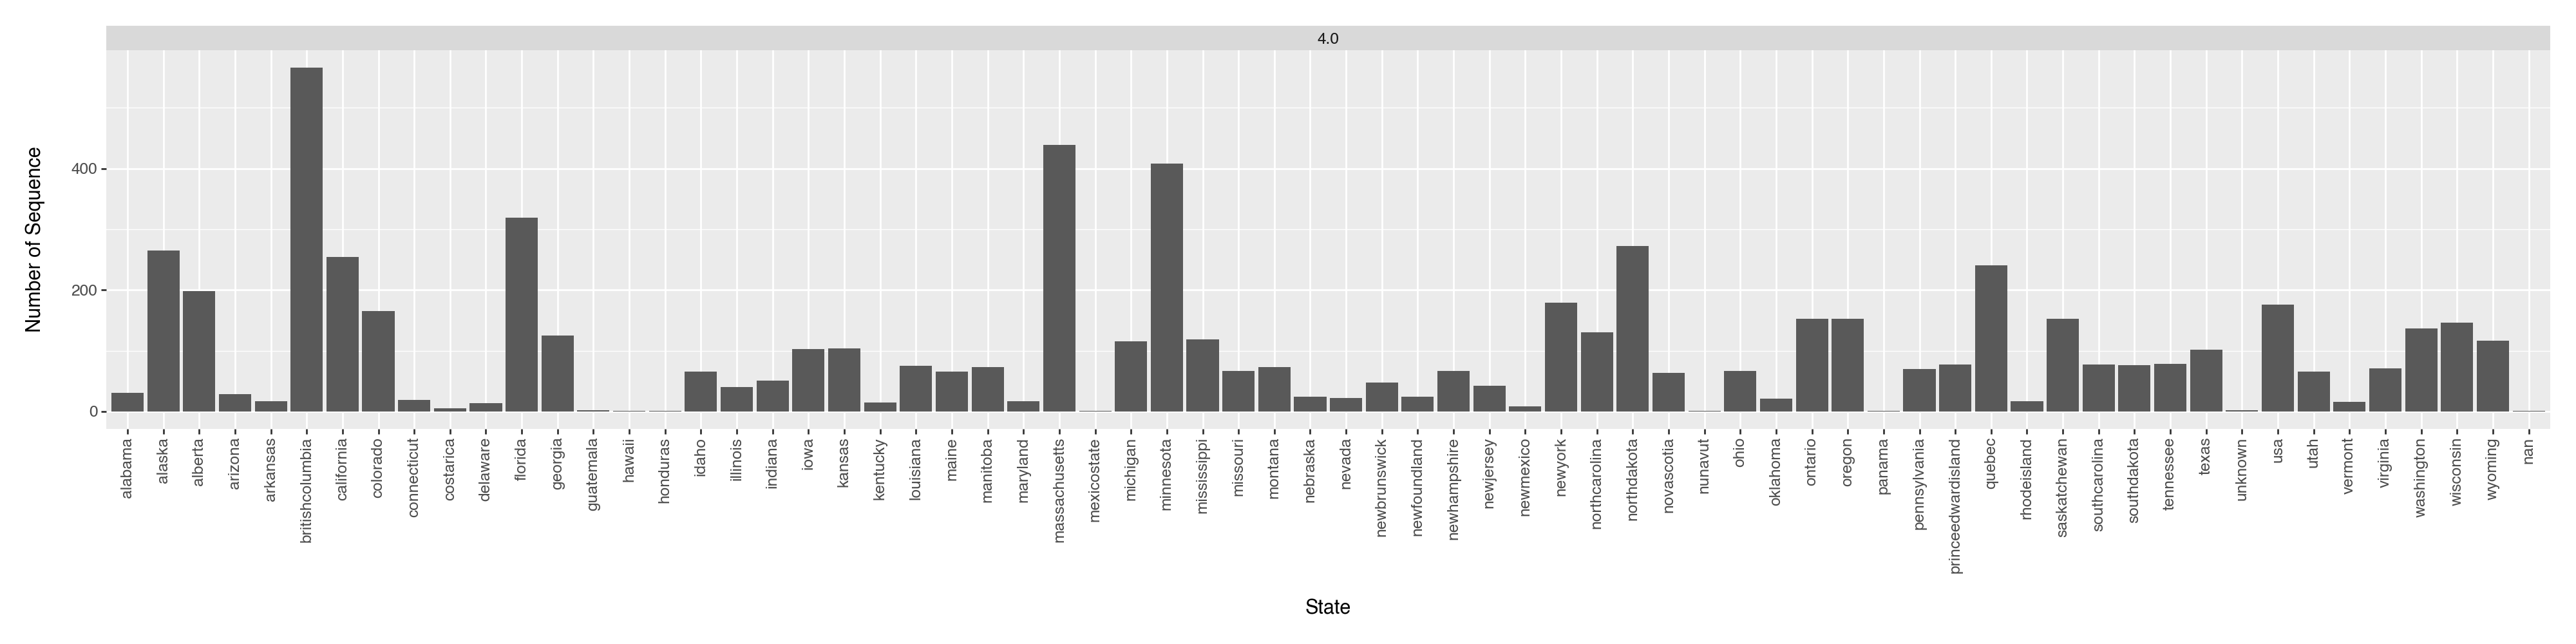

In [9]:
# Plot sequences by state, facetted by segment
by_state = (
    ggplot(ncbibvbrcgis_final, aes(x = "division"))
    + geom_bar(stat = "count")
    + facet_wrap("segment_no")
    + labs(x = "State", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (20, 5))
)

by_state.show()

#by_state.save(filename = './metadata/figures/seq_by_state.png', height=10, width=20, units = 'in', dpi=750)

In [10]:
# Which sequences have a blank nonambig_date?

no_date = ncbibvbrcgis_final[ncbibvbrcgis_final["nonambig_date"].isna()]
print(len(no_date)) # Only 16 sequences have no date... drop them

0


In [11]:
# Identify and drop rows where 'nonambig_date' is NaN
ncbibvbrcgis_final_drop_nan_date = ncbibvbrcgis_final[ncbibvbrcgis_final['nonambig_date'].notna()]

# Ensure that you have only lost 16 sequences
print(len(ncbibvbrcgis_final))
print(len(ncbibvbrcgis_final_drop_nan_date))

6737
6737


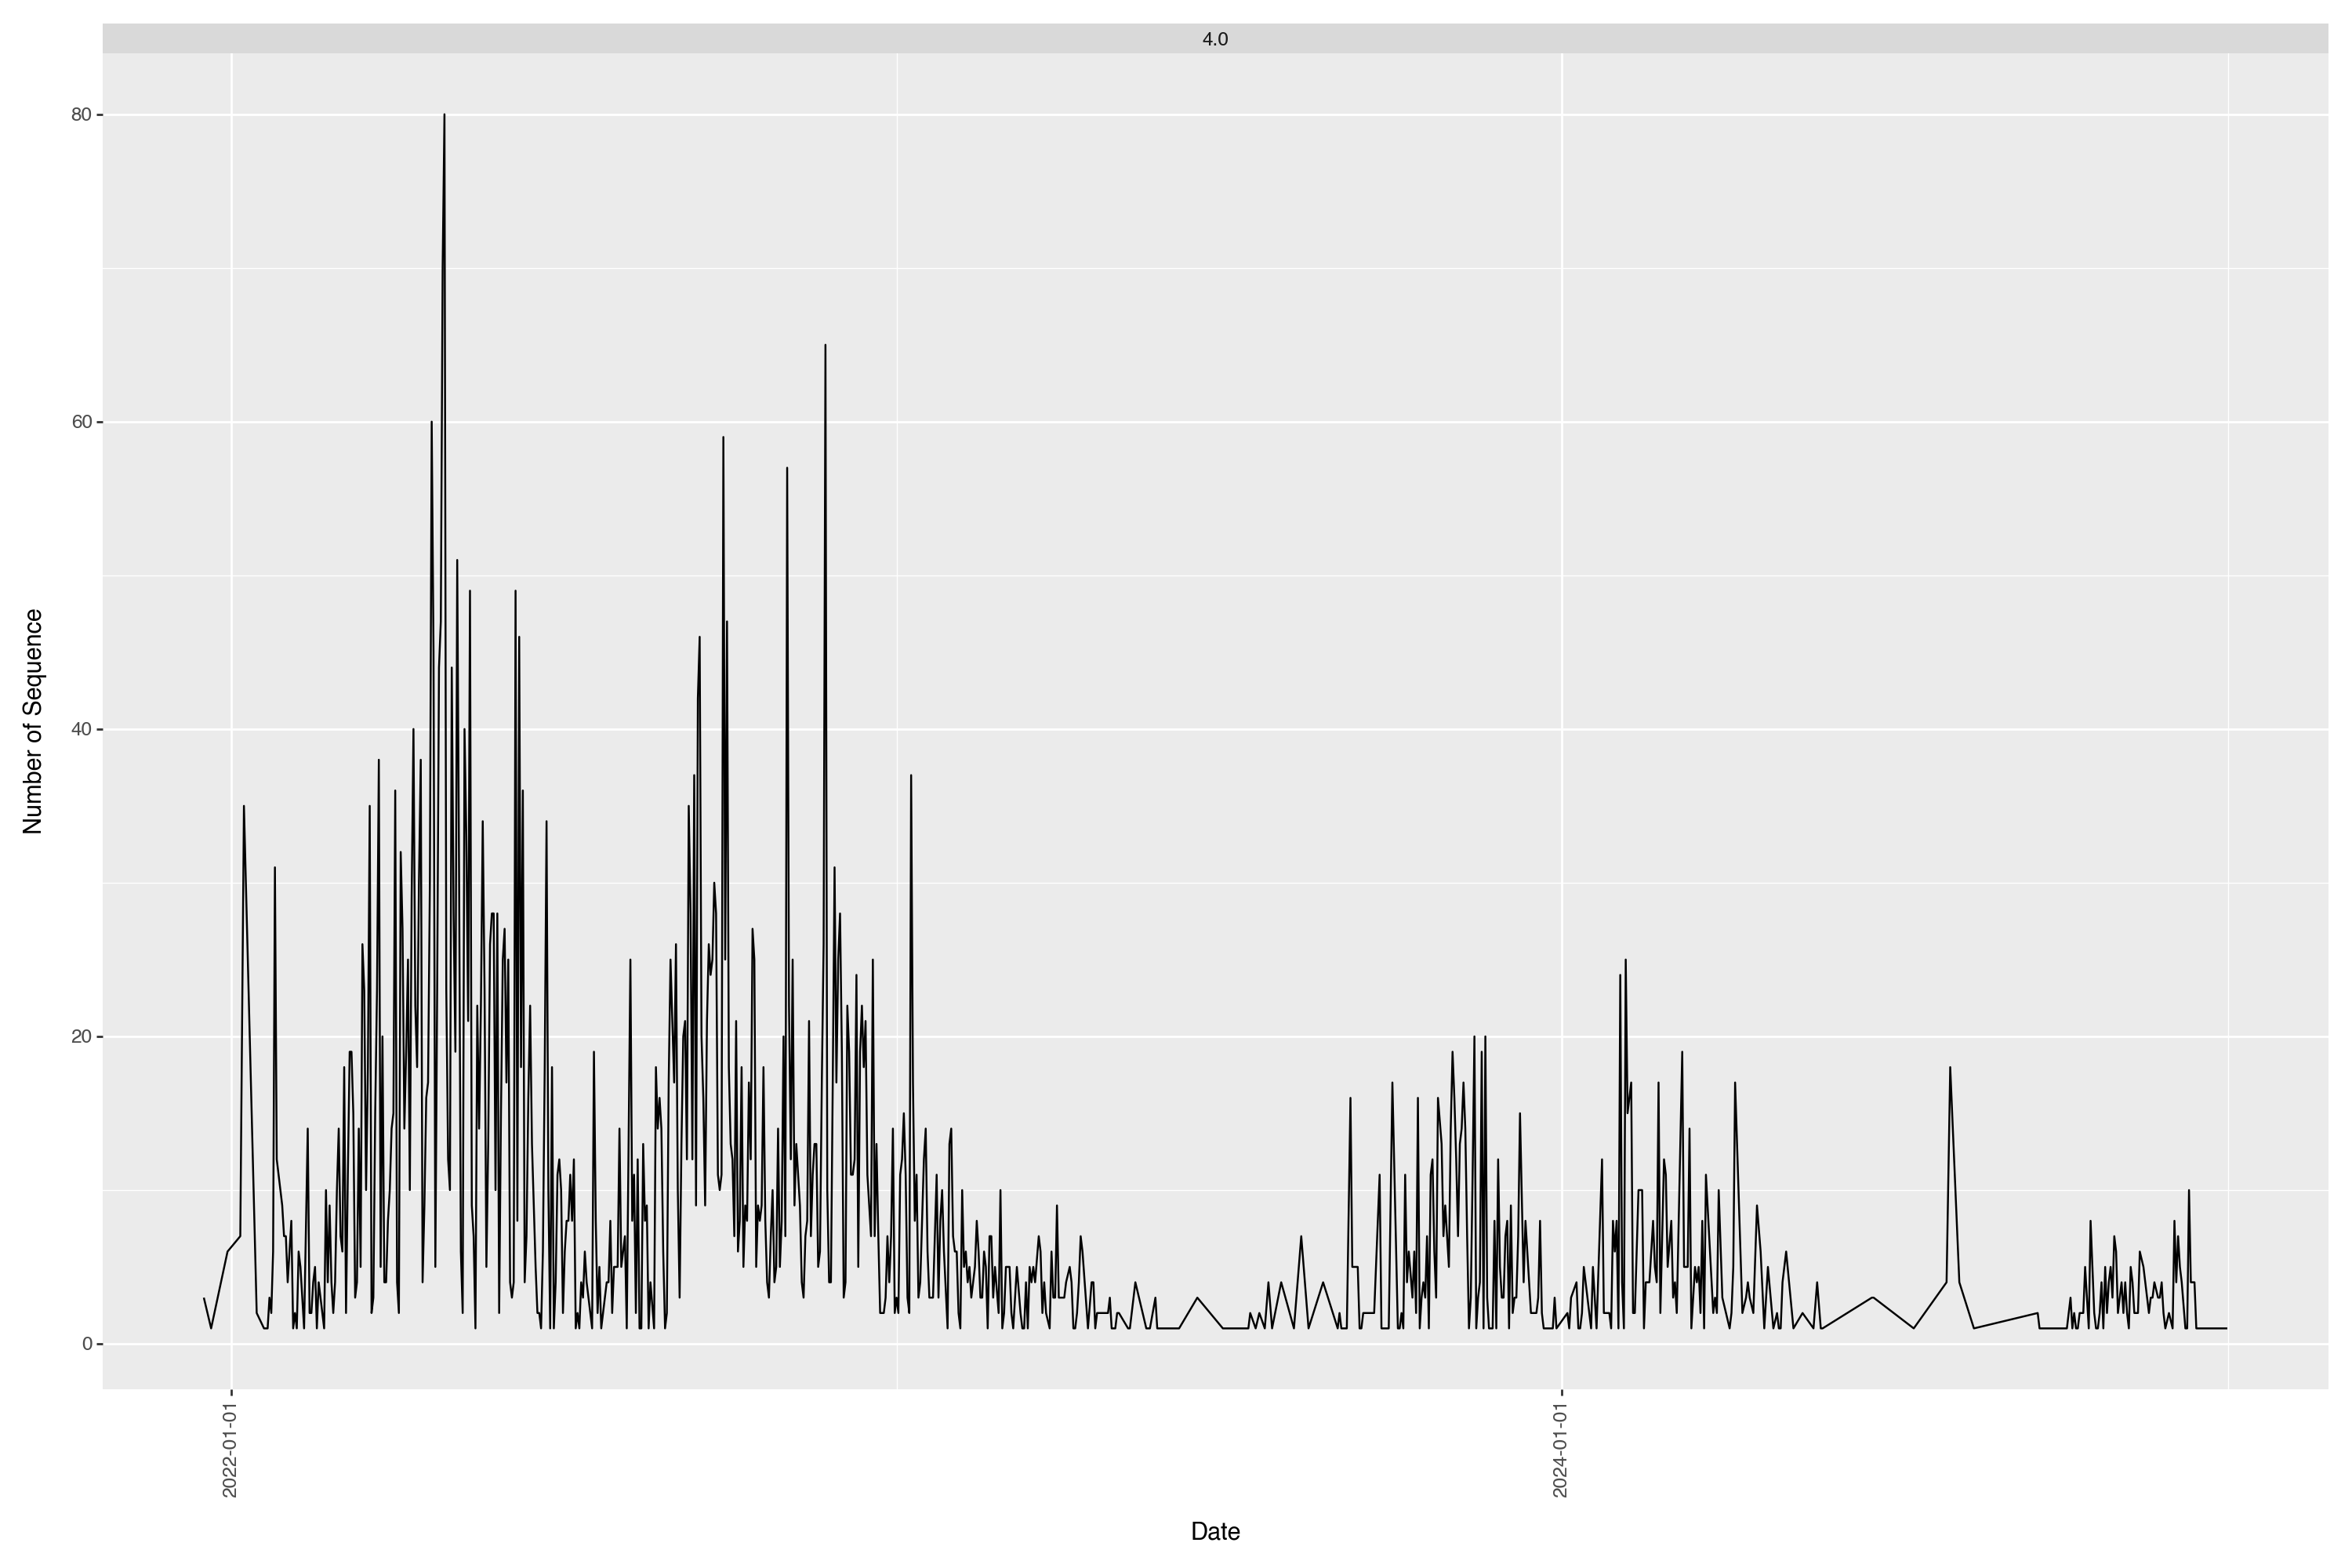

In [12]:
# Plot the number of sequences by date

ncbibvbrcgis_final_drop_nan_date["nonambig_date"] = ncbibvbrcgis_final_drop_nan_date["nonambig_date"].apply(format_date)

seq_over_time = (
    ggplot(ncbibvbrcgis_final_drop_nan_date, aes(x = "nonambig_date"))
    + geom_line(stat = "count")
    + facet_wrap("segment_no")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
)

seq_over_time.show()

#seq_over_time.save(filename = './metadata/figures/seq_over_time_2022-2024.png', height=10, width=20, units = 'in', dpi=750)

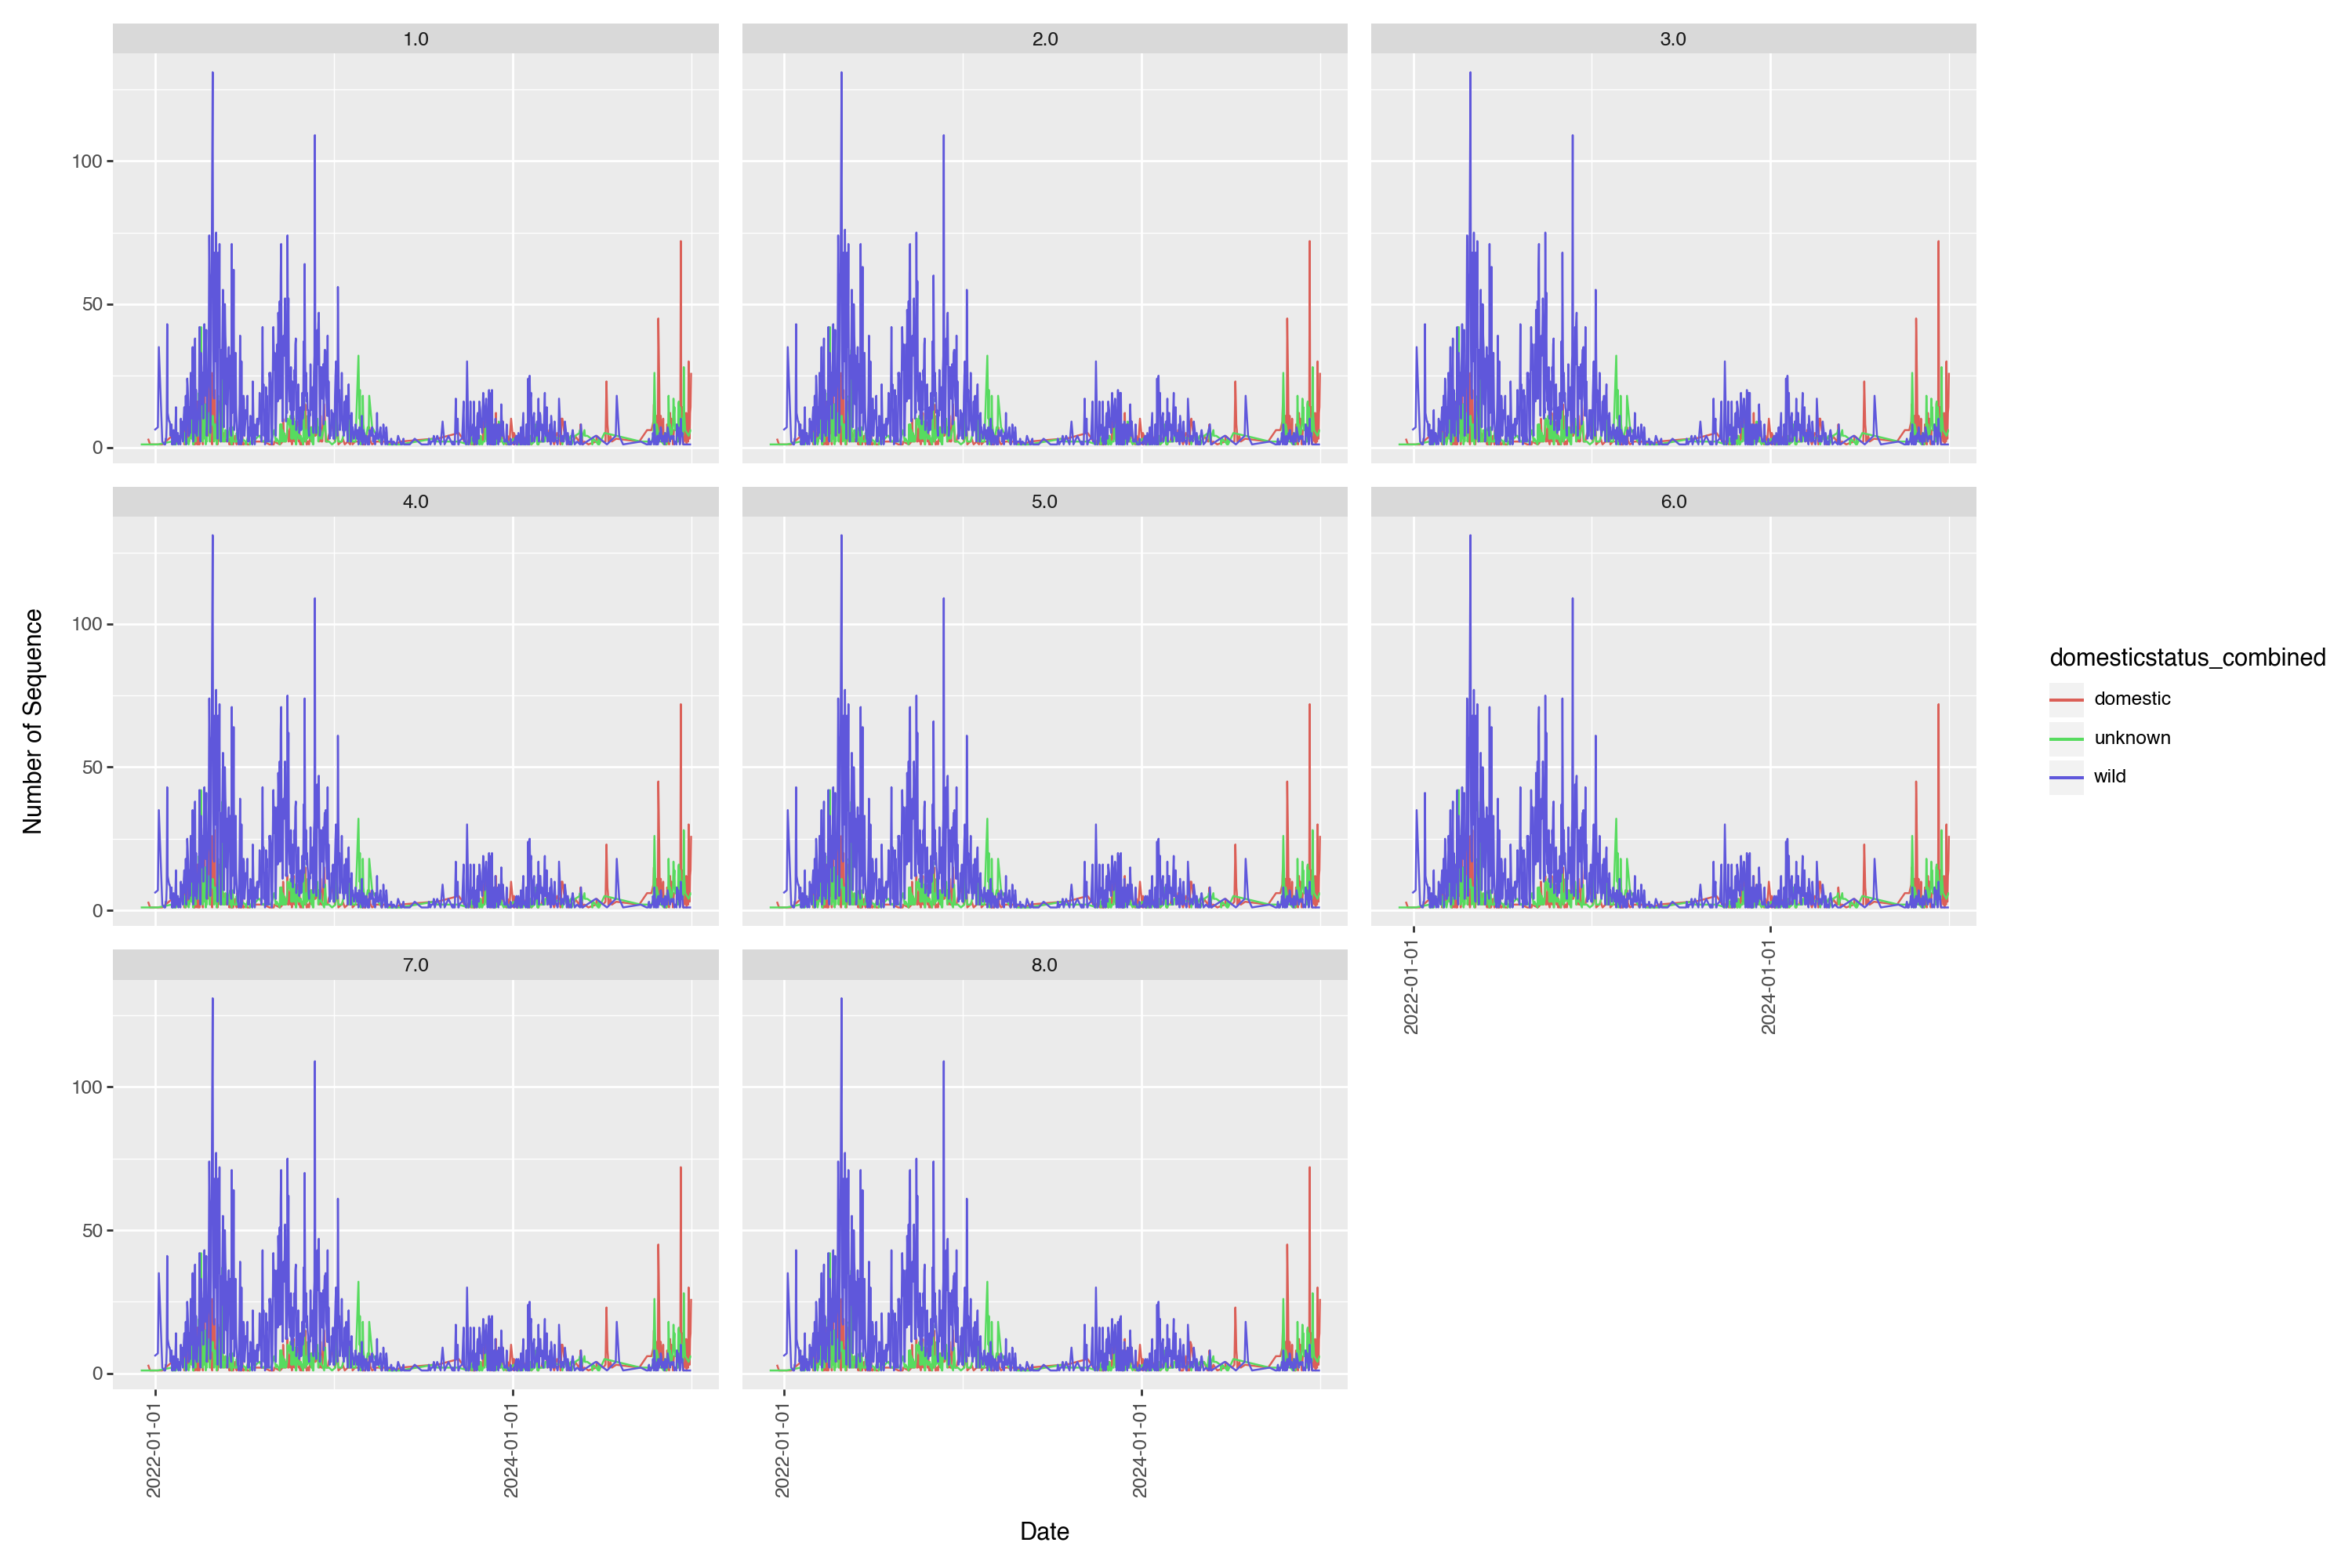

In [14]:
# Plot Sequences over time, with one line for wild birds and one line for domestic birds, facetted by segment
seq_over_time_domesticstatus = (
    ggplot(ncbibvbrcgis_final_drop_nan_date, aes(x = "nonambig_date", color = "domesticstatus_combined"))
    + geom_line(stat = "count")
    + facet_wrap("segment_no")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
)

seq_over_time_domesticstatus.show()

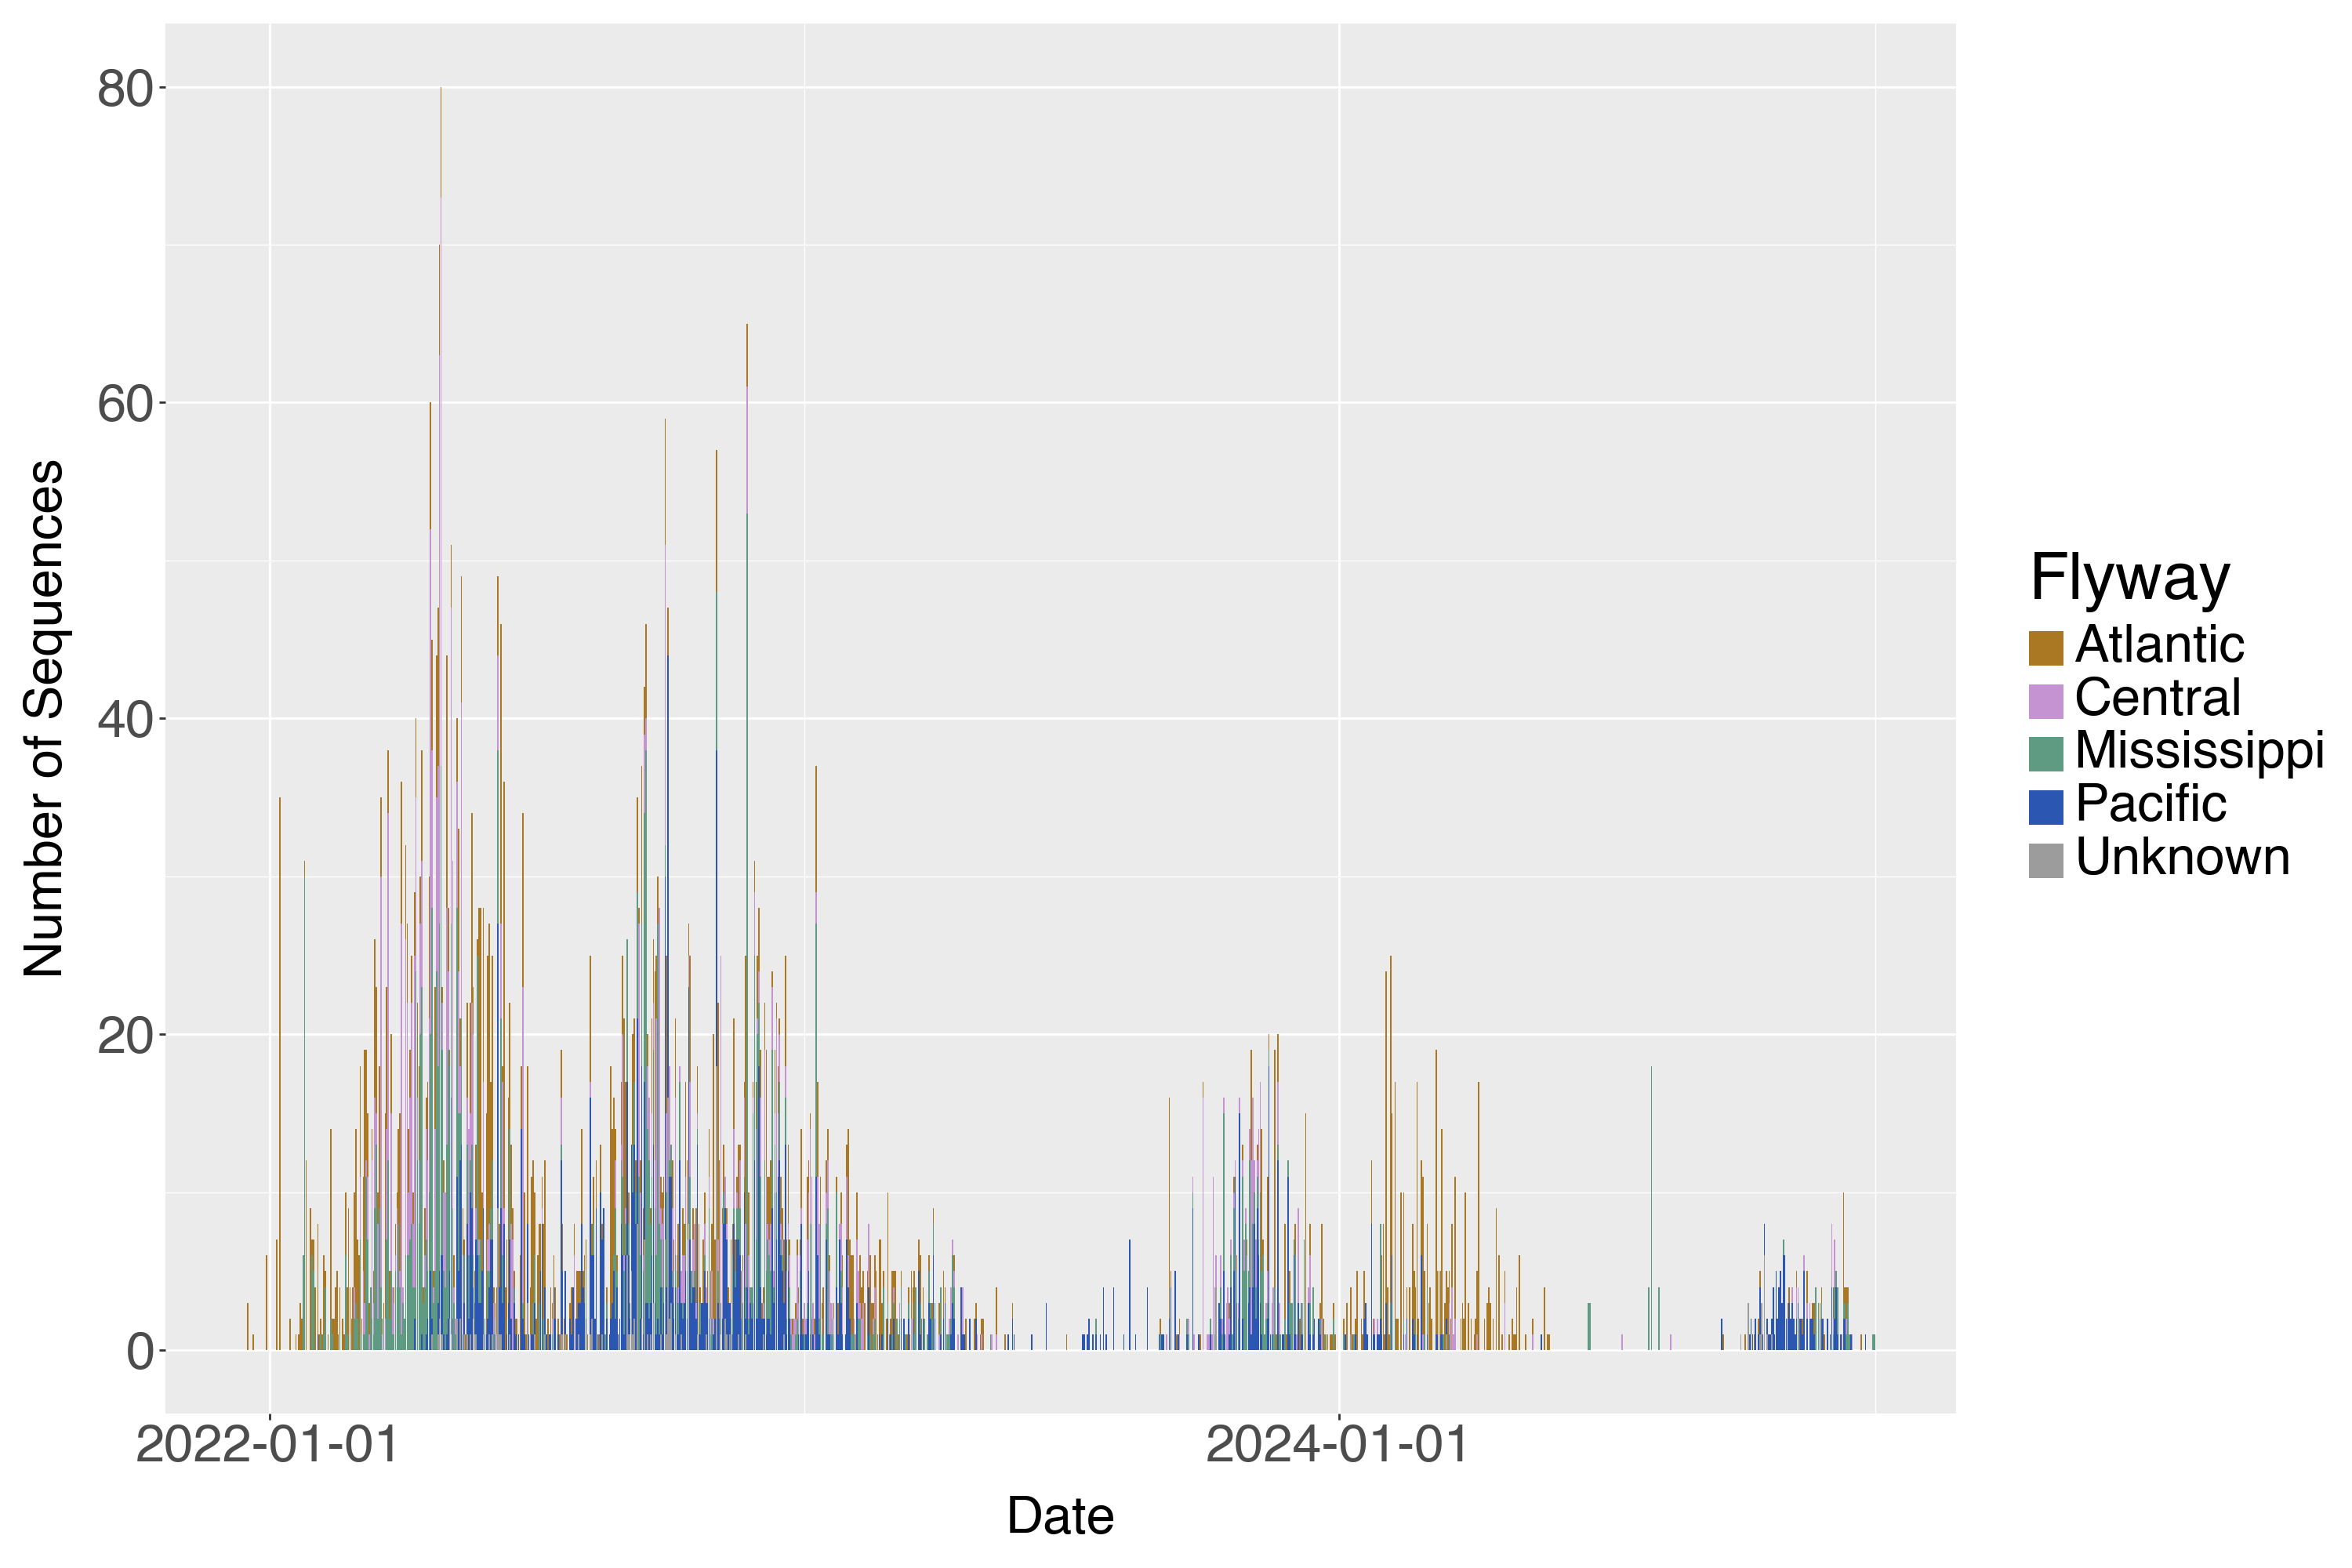

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./metadata/exploratory_data_analysis/HAseq_over_time_color-by-flyway.png


In [51]:
# Plot sequences over time, by flyway
# (
#     ggplot(ncbibvbrcgis_final, aes(x = "Collection_datetime", color = "flyway"))
#     + geom_line(stat = "count")
# #    + facet_wrap("Segment")
#     + labs(x = "Date", y = "Number of Sequence")
#     + theme(axis_text_x = element_text(rotation = 90), figure_size = (10, 5))
# )

ncbibvbrcgis_final_drop_nan_all = ncbibvbrcgis_final_drop_nan_date[~ncbibvbrcgis_final_drop_nan_date["NAflyway"].isna()]

# I don't love this as a line graph... what about as a bar graph
seq_over_time_flyway = (
    ggplot(ncbibvbrcgis_final_drop_nan_all, aes(x = "nonambig_date", fill = "NAflyway"))
    + geom_bar(stat = "count", size = 10)
    # + facet_wrap("segment_no")
    + scale_fill_manual(values = {"AtlanticFlyway":"#AA7722", "MississippiFlyway":"#5E9B82", "CentralFlyway":"#C593D1", "PacificFlyway":"#2B57B3", "unknown":"#9C9C9C"},
                        name = "Flyway",
                        labels = {"AtlanticFlyway":"Atlantic", "MississippiFlyway":"Mississippi", "CentralFlyway":"Central", "PacificFlyway":"Pacific", "unknown":"Unknown"})
    + labs(x = "Date", y = "Number of Sequences")
    + theme(axis_text_x = element_text(rotation = 0), 
            text=element_text(size=24),
            figure_size = (15, 10),
            legend_title=element_text(size=30),
            legend_text=element_text(size=24)
           )
)

# All those unknowns are probably people who put "usa" in the strain name

seq_over_time_flyway.show()

#seq_over_time_flyway.save(filename = './metadata/figures/seq_over_time_flyway.png', height=10, width=20, units = 'in', dpi=750)
seq_over_time_flyway.save(filename = './metadata/exploratory_data_analysis/HAseq_over_time_color-by-flyway.png', height=10, width=20, units = 'in', dpi=750)

In [16]:
# Where are sequences from?

print(ncbibvbrcgis_final["source_merge2"].value_counts())

source_merge2
gisaid               61393
ncbi-bvbrc           35490
ncbi-bvbrc-gisaid     2018
ncbi                  1895
bvbrc                 1649
ncbi-gisaid            686
bvbrc-gisaid            32
Name: count, dtype: int64


In [17]:
# How many sequences per flyway

# Total sequences per flyway (ALL segments)
print(ncbibvbrcgis_final["NAflyway"].value_counts())

NAflyway
AtlanticFlyway       27475
MississippiFlyway    26870
PacificFlyway        26417
CentralFlyway        20701
unknown               1612
Name: count, dtype: int64


In [18]:
# How many sequences per year

print(ncbibvbrcgis_final["year_only"].value_counts())

year_only
2022    69549
2023    17863
2024    15663
2021       88
Name: count, dtype: int64


In [19]:
# Flyway count by segment

ncbibvbrcgis_pb2 = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 1.0] 
ncbibvbrcgis_pb1 = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 2.0] 
ncbibvbrcgis_pa = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 3.0] 
ncbibvbrcgis_ha = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 4.0] 
ncbibvbrcgis_np = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 5.0] 
ncbibvbrcgis_na = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 6.0] 
ncbibvbrcgis_m = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 7.0] 
ncbibvbrcgis_ns = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 8.0]

print(ncbibvbrcgis_pb2["NAflyway"].value_counts())
print(ncbibvbrcgis_pb1["NAflyway"].value_counts())
print(ncbibvbrcgis_pa["NAflyway"].value_counts())
print(ncbibvbrcgis_ha["NAflyway"].value_counts())
print(ncbibvbrcgis_np["NAflyway"].value_counts())
print(ncbibvbrcgis_na["NAflyway"].value_counts())
print(ncbibvbrcgis_m["NAflyway"].value_counts())
print(ncbibvbrcgis_ns["NAflyway"].value_counts())

NAflyway
AtlanticFlyway       3427
MississippiFlyway    3357
PacificFlyway        3232
CentralFlyway        2585
unknown               183
Name: count, dtype: int64
NAflyway
AtlanticFlyway       3432
MississippiFlyway    3358
PacificFlyway        3214
CentralFlyway        2586
unknown               189
Name: count, dtype: int64
NAflyway
AtlanticFlyway       3429
MississippiFlyway    3357
PacificFlyway        3269
CentralFlyway        2586
unknown               197
Name: count, dtype: int64
NAflyway
AtlanticFlyway       3439
MississippiFlyway    3359
PacificFlyway        3354
CentralFlyway        2588
unknown               211
Name: count, dtype: int64
NAflyway
AtlanticFlyway       3439
MississippiFlyway    3358
PacificFlyway        3338
CentralFlyway        2588
unknown               206
Name: count, dtype: int64
NAflyway
AtlanticFlyway       3431
MississippiFlyway    3357
PacificFlyway        3350
CentralFlyway        2588
unknown               208
Name: count, dtype: int64
NAflyway
A

In [20]:
print(len(ncbibvbrcgis_pb2))
print(len(ncbibvbrcgis_pb1))
print(len(ncbibvbrcgis_pa))
print(len(ncbibvbrcgis_ha))
print(len(ncbibvbrcgis_np))
print(len(ncbibvbrcgis_na))
print(len(ncbibvbrcgis_m))
print(len(ncbibvbrcgis_ns))

12795
12790
12849
12962
12940
12945
12934
12948


In [21]:
# How many full viral genome sequences from wild birds?

ncbibvbrcgis_wild = ncbibvbrcgis_final[ncbibvbrcgis_final["domesticstatus_combined"] == "wild"]

strain_counts = ncbibvbrcgis_wild["strain_title"].value_counts()

all_wild_full = []

for strain, count in strain_counts.items():
    if count == 8:
        all_wild_full.append(strain)

print(len(all_wild_full))

# January 21, 2025 pull: 8014 full wild seqs
# May 25, 2025 pull: 8691 full wild seqs

8691


In [22]:
# How many wild bird sequences across the years?

print(len(ncbibvbrcgis_wild))
print(ncbibvbrcgis_wild["year_only"].value_counts())

70833
year_only
2022    53434
2023    11442
2024     5909
2021       48
Name: count, dtype: int64


In [23]:
# Make metadata for just the wild birds

ncbibvbrcgis_wild_pb2 = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 1.0]
ncbibvbrcgis_wild_pb1 = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 2.0]
ncbibvbrcgis_wild_pa = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 3.0]
ncbibvbrcgis_wild_ha = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 4.0]
ncbibvbrcgis_wild_np = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 5.0]
ncbibvbrcgis_wild_na = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 6.0]
ncbibvbrcgis_wild_m = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 7.0]
ncbibvbrcgis_wild_ns = ncbibvbrcgis_wild[ncbibvbrcgis_wild["segment_no"] == 8.0]

print(len(ncbibvbrcgis_wild_pb2))
print(len(ncbibvbrcgis_wild_pb1))
print(len(ncbibvbrcgis_wild_pa))
print(len(ncbibvbrcgis_wild_ha))
print(len(ncbibvbrcgis_wild_np))
print(len(ncbibvbrcgis_wild_na))
print(len(ncbibvbrcgis_wild_m))
print(len(ncbibvbrcgis_wild_ns))

8775
8765
8818
8907
8894
8891
8892
8891


In [24]:
# Count of sequences per flyway for wild birds only

print(ncbibvbrcgis_wild["NAflyway"].value_counts())

NAflyway
AtlanticFlyway       21507
MississippiFlyway    17525
PacificFlyway        16751
CentralFlyway        13686
unknown               1356
Name: count, dtype: int64


In [25]:
# What is the breakdown of host orders in wild birds

print(ncbibvbrcgis_wild["bird_order"].value_counts())

bird_order
anseriformes         32722
accipitriformes      18828
charadriiformes       5318
strigiformes          5174
passeriformes         3655
pelecaniformes        1708
suliformes            1240
falconiformes         1044
podicipediformes       472
gaviiformes            176
galliformes            152
gruiformes             144
columbiformes          120
procellariiformes       24
unknown                 24
ciconiiformes           16
apodiformes             16
Name: count, dtype: int64


In [26]:
# Count of sequences per source database for wild birds only

print(ncbibvbrcgis_wild["source_merge2"].value_counts())

source_merge2
gisaid               40222
ncbi-bvbrc           25333
bvbrc                 1634
ncbi                  1588
ncbi-bvbrc-gisaid     1338
ncbi-gisaid            686
bvbrc-gisaid            32
Name: count, dtype: int64


In [27]:
# Counts of HA-only sequences for wild birds

print(ncbibvbrcgis_wild_ha["NAflyway"].value_counts())
print(ncbibvbrcgis_wild_ha["bird_order"].value_counts())
print(ncbibvbrcgis_wild_ha["year_only"].value_counts())
print(ncbibvbrcgis_wild_ha["source_merge2"].value_counts())

NAflyway
AtlanticFlyway       2693
MississippiFlyway    2192
PacificFlyway        2132
CentralFlyway        1711
unknown               178
Name: count, dtype: int64
bird_order
anseriformes         4121
accipitriformes      2362
charadriiformes       668
strigiformes          650
passeriformes         461
pelecaniformes        216
suliformes            155
falconiformes         131
podicipediformes       59
gaviiformes            22
galliformes            19
gruiformes             18
columbiformes          15
procellariiformes       3
unknown                 3
ciconiiformes           2
apodiformes             2
Name: count, dtype: int64
year_only
2022    6718
2023    1439
2024     744
2021       6
Name: count, dtype: int64
source_merge2
gisaid               5070
ncbi-bvbrc           3168
bvbrc                 204
ncbi                  199
ncbi-bvbrc-gisaid     176
ncbi-gisaid            86
bvbrc-gisaid            4
Name: count, dtype: int64


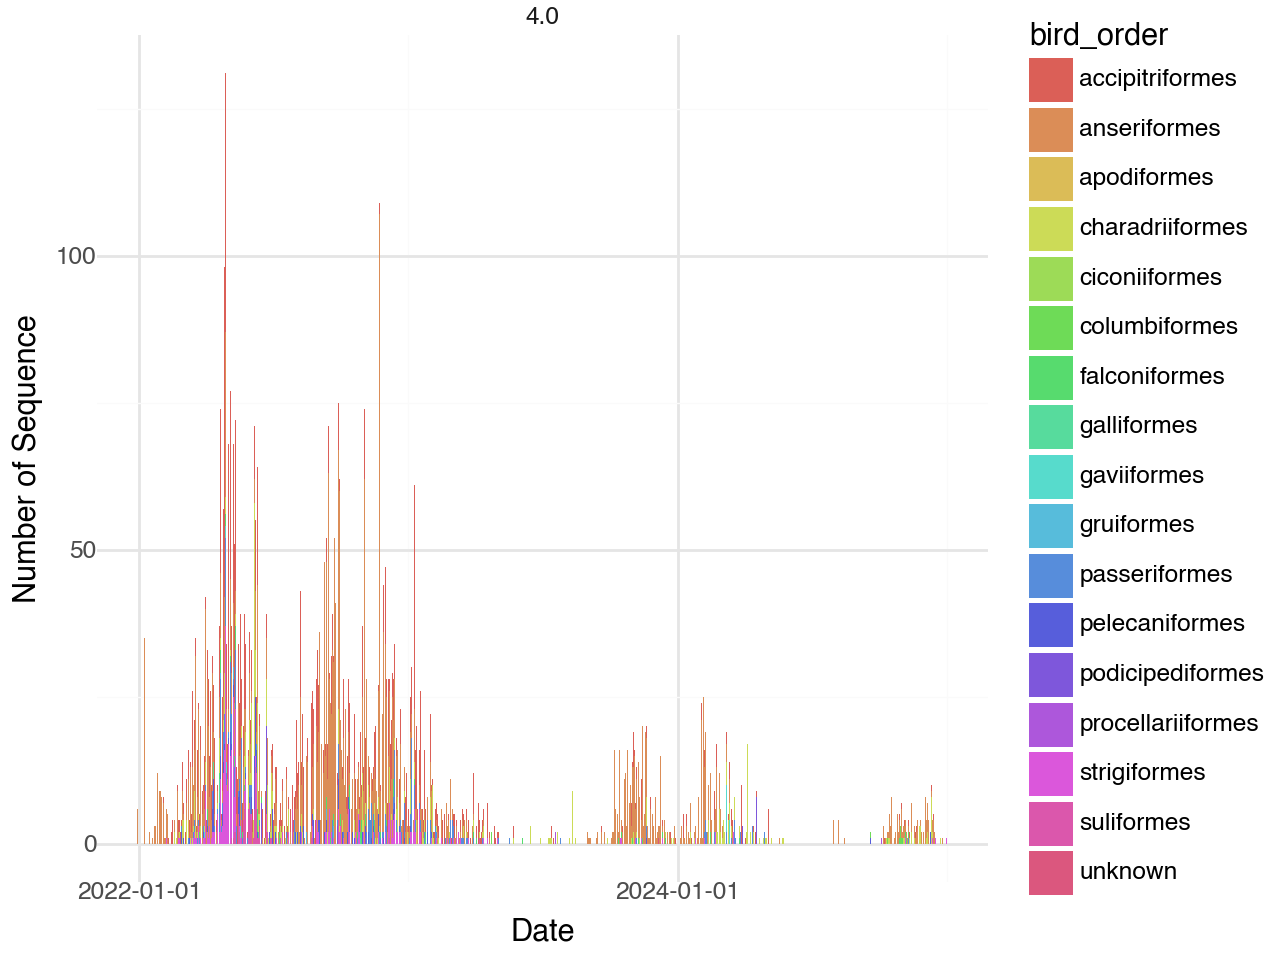

In [28]:
# Breakdown of sequences over time by bird order

ncbibvbrcgis_wild_ha_drop_nan_date = ncbibvbrcgis_wild_ha[ncbibvbrcgis_wild_ha['nonambig_date'].notna()]
ncbibvbrcgis_wild_ha_drop_nan_date["nonambig_date"] = ncbibvbrcgis_wild_ha_drop_nan_date["nonambig_date"].apply(format_date)

# seq_over_time_order = (
#     ggplot(ncbibvbrcgis_wild_ha_drop_nan_date, aes(x = "nonambig_date", color = "bird_order"))
#     + geom_line(stat = "count")
#     + facet_wrap("segment_no")
#     + labs(x = "Date", y = "Number of Sequence")
#     + theme(axis_text_x = element_text(rotation = 90), figure_size = (15, 10))
# )

seq_over_time_order = (
    ggplot(ncbibvbrcgis_wild_ha_drop_nan_date, aes(x = "nonambig_date", fill = "bird_order"))
    + geom_bar(stat = "count", size = 10)
    + facet_wrap("segment_no")
    + labs(x = "Date", y = "Number of Sequence")
    + theme(axis_text_x = element_text(rotation = 90), text = element_text(size = 18))
    + theme_minimal()
)


seq_over_time_order.show()

#seq_over_time_order.save(filename = './metadata/figures/seq_by_birdorder.png', height=10, width=20, units = 'in', dpi=750)

In [29]:
# HA sequences from wild birds over time, colored by county level coordinates

# Read in the HA dataset with detections data
INPUT = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv"
ncbibvbrcgis_ha_geodata = pd.read_csv(INPUT, sep = "\t")

# Subset to just wild birds
ncbibvbrcgis_ha_geodata_wild = ncbibvbrcgis_ha_geodata[ncbibvbrcgis_ha_geodata["domesticstatus_combined"] == "wild"]
#ncbibvbrcgis_ha_geodata_wild.head()

# Make a year_month column
ncbibvbrcgis_ha_geodata_wild["year_only"] = ncbibvbrcgis_ha_geodata_wild["year_only"].astype(str).str.replace(".0", "")
ncbibvbrcgis_ha_geodata_wild["month_only"] = ncbibvbrcgis_ha_geodata_wild["month_only"].astype(str).str.replace(".0", "").str.zfill(2)
ncbibvbrcgis_ha_geodata_wild["year_month"] = ncbibvbrcgis_ha_geodata_wild[["year_only", "month_only"]].agg("/".join, axis = 1)

# Subset dataframe to just lat_long_source and year_month for ease, and bin by year_month
columns = ["lat_long_source", "year_month"]
ncbibvbrcgis_ha_geodata_wild_SUBSET = ncbibvbrcgis_ha_geodata_wild.loc[0:, columns] # Filter
ncbibvbrcgis_ha_geodata_wild_SUBSET["year_month"] = ncbibvbrcgis_ha_geodata_wild_SUBSET["year_month"].astype(str) # Make year_month a string
ncbibvbrcgis_ha_geodata_wild_SUBSET["year_month"] = ncbibvbrcgis_ha_geodata_wild_SUBSET["year_month"].replace(["nan", "nan/nan"], np.nan) # Convert nan strings to actual NaN
ncbibvbrcgis_ha_geodata_wild_SUBSET = ncbibvbrcgis_ha_geodata_wild_SUBSET.dropna(subset=["year_month"]) # Drop NaN
ncbibvbrcgis_ha_geodata_wild_SUBSET = (ncbibvbrcgis_ha_geodata_wild_SUBSET.sort_values('year_month').reset_index(drop=True)) # Sort by year_month
# ncbibvbrcgis_ha_geodata_wild_SUBSET.head()

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_38997/4040624213.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_38997/4040624213.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_38997/4040624213.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the doc

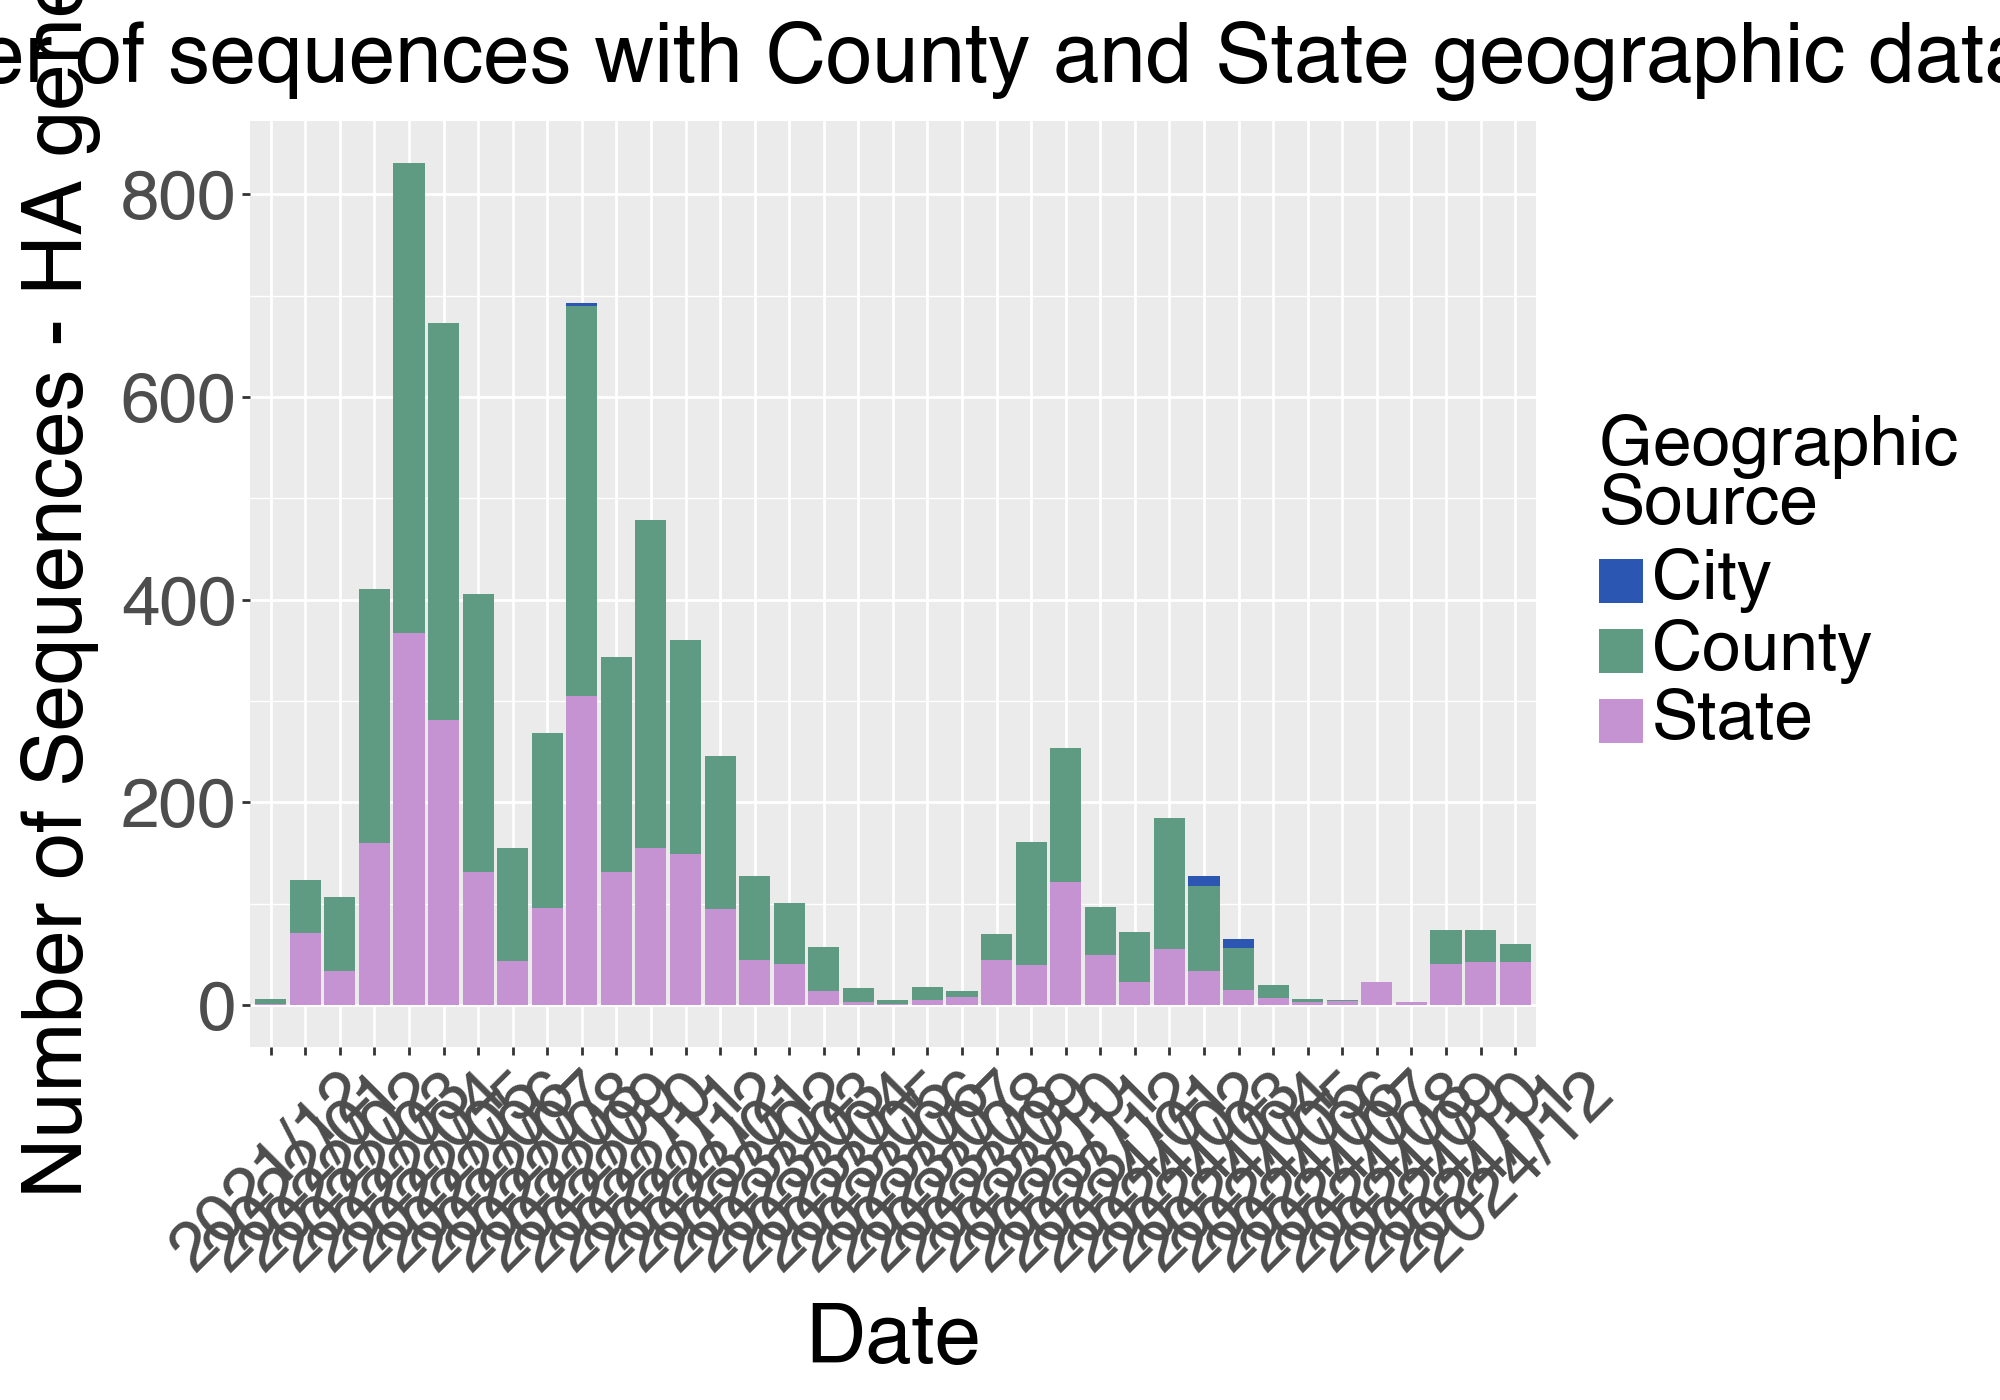

In [31]:
# Custom colors and labels
colors = {"county":"#5E9B82", "state":"#C593D1", "city":"#2B57B3"}
labels = {"county":"County", "state":"State", "city":"City", "nan": "Unknown"}

# Plot
lat_long_source_year_month = (
    ggplot(ncbibvbrcgis_ha_geodata_wild_SUBSET, aes(x = "year_month", fill = "lat_long_source"))
    + geom_col(stat = "count")
    + theme(axis_text_x=element_text(rotation=45, size = 25))
    + theme(axis_text_y=element_text(size = 25))
    + theme(figure_size = (10, 7))
    + labs(x = "Date", y = "Number of Sequences - HA gene", title = "Number of sequences with County and State geographic data", fill = "Geographic \nSource")
    + theme(axis_title_x = element_text(size = 30))
    + theme(axis_title_y = element_text(size = 30))
    + theme(legend_text = element_text(size = 25))
    + theme(legend_title = element_text(size = 25))
    + theme(plot_title = element_text(size = 30))
    + scale_fill_manual(values=colors, labels=labels)
)

lat_long_source_year_month.show()
#lat_long_source_year_month.save("./metadata/exploratory_data_analysis/HA_geographicsource_overtime.png", height=10, width=20, units = 'in', dpi=750)

In [33]:
# Unique coordinates and repeate coordinates in HA sequences from wild birds

In [6]:
# Limit to just nonambig_date and lat_long_to_use
columns = ["year_month", "lat_long_to_use", "division"]
ncbibvbrcgis_ha_geodata_wild_SUBSET2 = ncbibvbrcgis_ha_geodata_wild.loc[0:, columns]
ncbibvbrcgis_ha_geodata_wild_SUBSET2["Count"] = "total"
print(len(ncbibvbrcgis_ha_geodata_wild))
ncbibvbrcgis_ha_geodata_wild_SUBSET2.head()

8904


,year_month,lat_long_to_use,division,Count
0,2022/02,"41.47,-72.1",connecticut,total
1,2022/02,"41.35,-72.9",connecticut,total
2,2022/02,"41.35,-72.9",connecticut,total
3,2022/02,"41.35,-72.9",connecticut,total
4,2023/11,"41.284478,-86.644636",indiana,total


In [8]:
# Function: make a count of unique lat/longs per year_month
def uniquelatlong_date(df):
    unique_latlongs = {}

    for idx, row in df.iterrows():
        year_month = row["year_month"]
        lat_long = row["lat_long_to_use"]

        # Add each unique lat-long to a dictionary
        if year_month not in unique_latlongs:
            unique_latlongs[year_month] = set()
        unique_latlongs[year_month].add(lat_long)
        
    # Convert the sets of unique lat/longs to counts
    unique_counts = {k: len(v) for k, v in unique_latlongs.items()}   

    return unique_counts

In [9]:
# Make a dictionary of the number of unique lat/longs per date
unique_per_date = uniquelatlong_date(ncbibvbrcgis_ha_geodata_wild_SUBSET2)

# Convert this to a dataframe
unique_per_date_df = pd.DataFrame(list(unique_per_date.items()), columns=['year_month', 'unique_latlong_count'])
unique_per_date_df["Count"] = "unique"
unique_per_date_df.head()
print(unique_per_date_df["year_month"].dtypes)

object


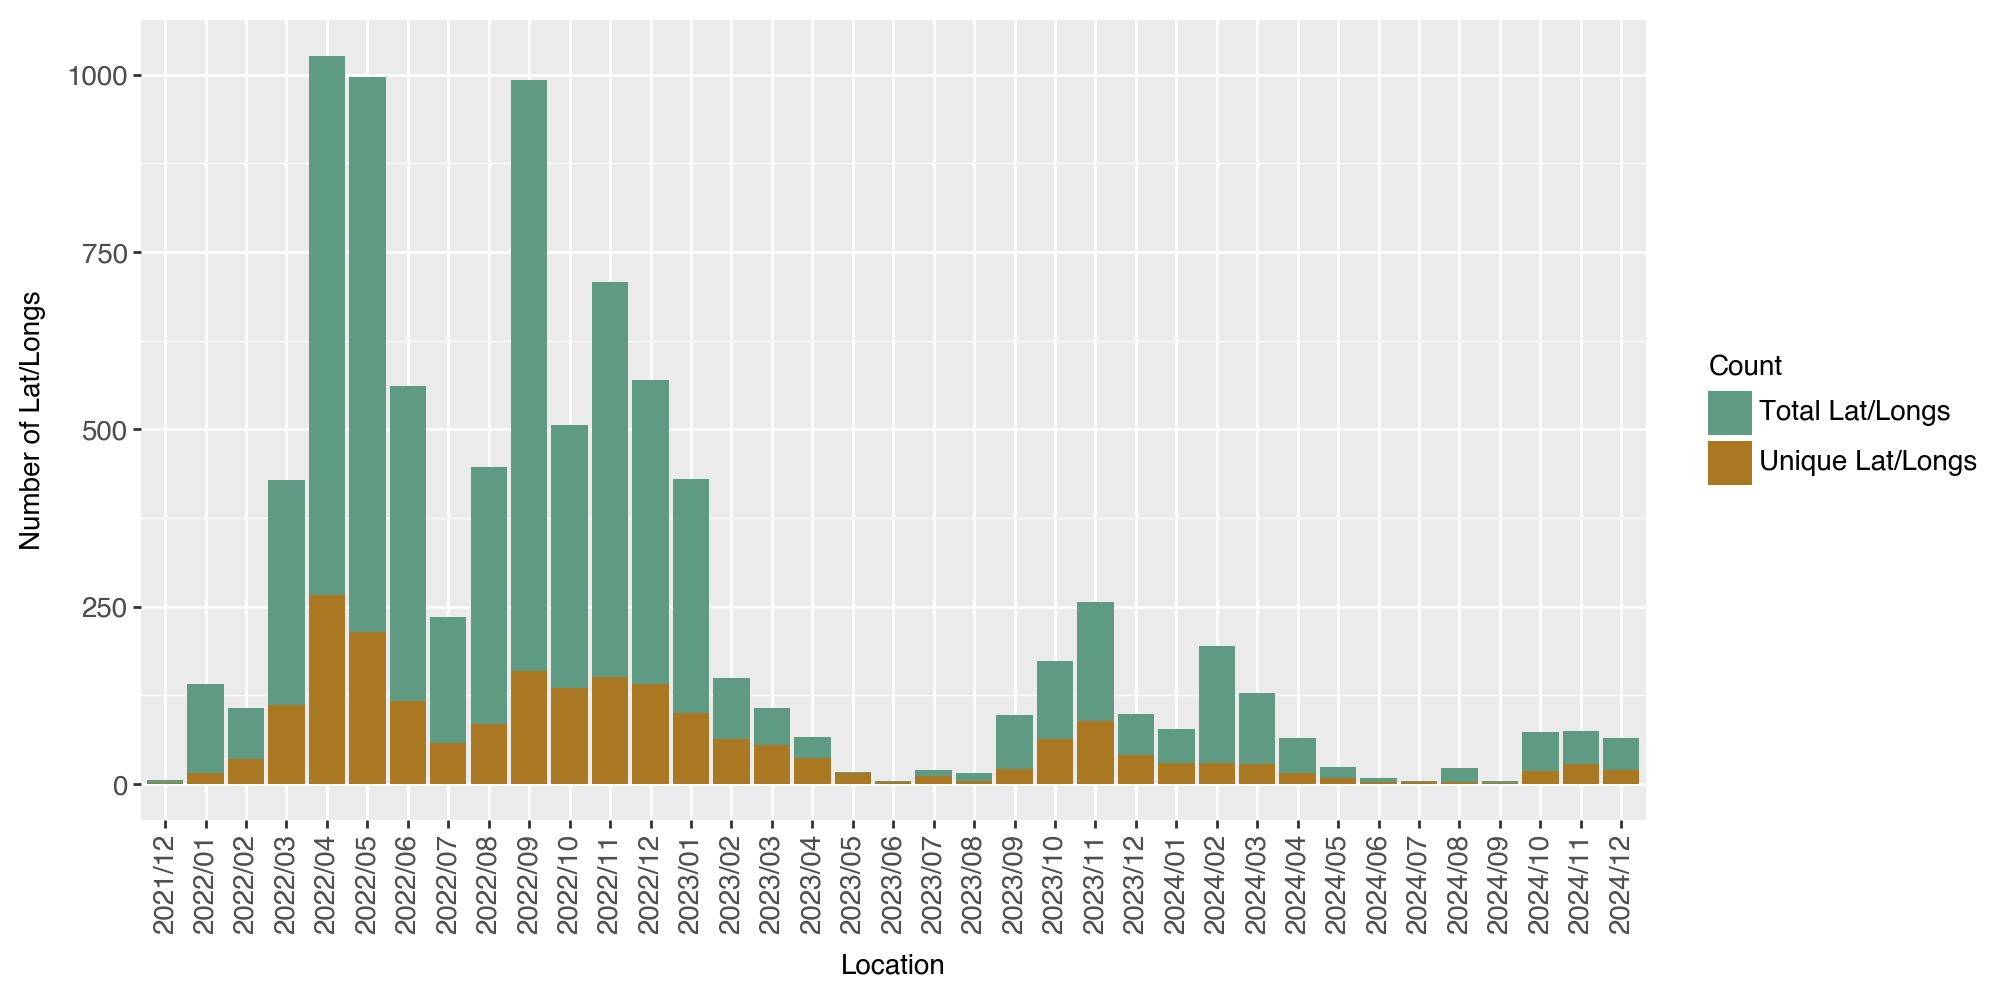

In [10]:
# Plot
uniquelatlong_per_division = (
    ggplot()
    + geom_col(data=ncbibvbrcgis_ha_geodata_wild_SUBSET2, mapping=aes(x='year_month', fill='Count'), stat='count', position='dodge')
    + geom_col(data=unique_per_date_df, mapping=aes(x='year_month', y='unique_latlong_count', fill='Count'), position='dodge')
    + scale_fill_manual(values={"total":"#5E9B82", "unique": "#AA7722"}, name="Count", labels={"total":"Total Lat/Longs", "unique": "Unique Lat/Longs"})
    + labs(x='Location', y='Number of Lat/Longs')
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
    + theme(figure_size=(10, 5))
)

uniquelatlong_per_division.show()
#uniquelatlong_per_division.save(filename = './metadata/exploratory_data_analysis/2022-2024_latlongs_by_location.png', height=10, width=20, units = 'in', dpi=750)

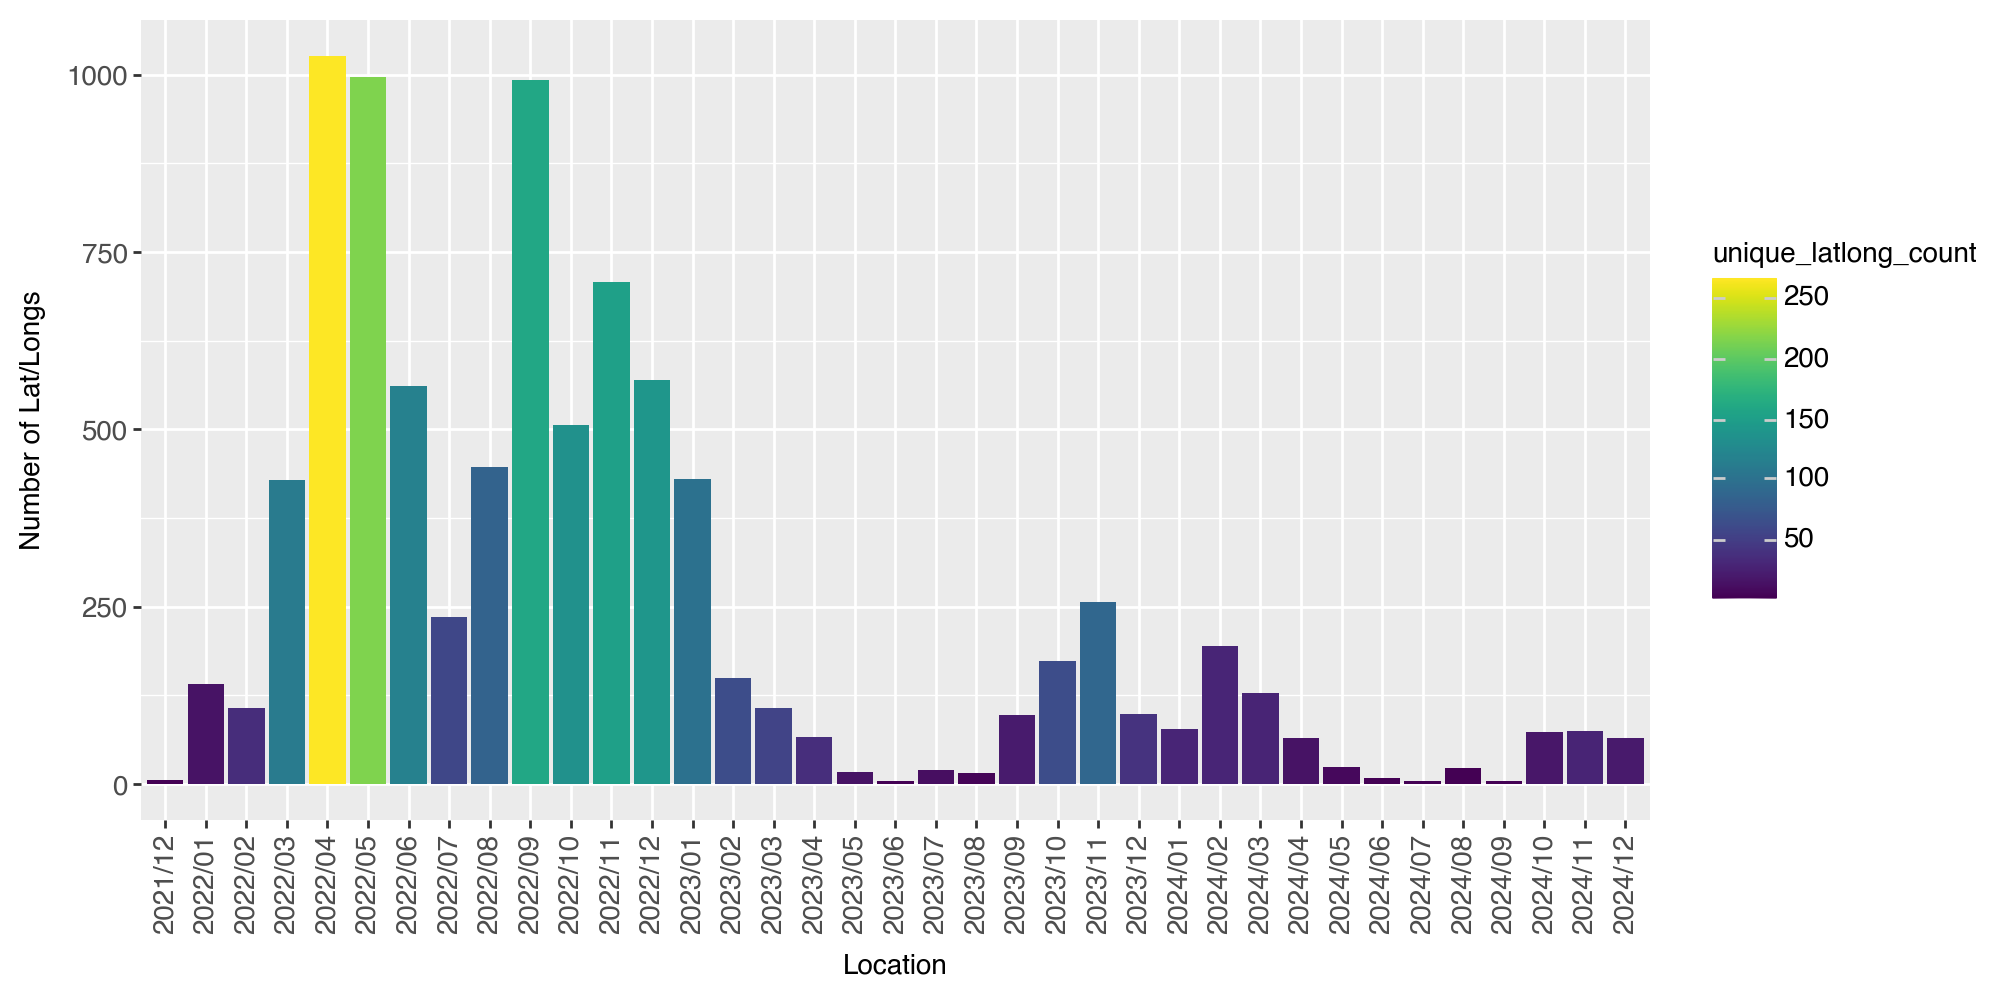

In [11]:
# Merge 
merged = ncbibvbrcgis_ha_geodata_wild_SUBSET2.merge(unique_per_date_df, on="year_month")

# Plot
testy = (
    ggplot()
    + geom_col(data=merged, mapping=aes(x='year_month', fill='unique_latlong_count'), stat='count', position='dodge')
#    + geom_col(data=unique_per_date_df, mapping=aes(x='year_month', y='unique_latlong_count', fill='Count'), position='dodge')
#    + scale_fill_manual(values={"total":"#5E9B82", "unique": "#AA7722"}, name="Count", labels={"total":"Total Lat/Longs", "unique": "Unique Lat/Longs"})
    + labs(x='Location', y='Number of Lat/Longs')
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
    + theme(figure_size=(10, 5))
)

testy.show()

In [12]:
# Function: make a count of unique lat/longs per division
def uniquelatlong_division(df):
    unique_latlongs = {}

    for idx, row in df.iterrows():
        division = row["division"]
        lat_long = row["lat_long_to_use"]

        # Add each unique lat-long to a dictionary
        if division not in unique_latlongs:
            unique_latlongs[division] = set()
        unique_latlongs[division].add(lat_long)
        
    # Convert the sets of unique lat/longs to counts
    unique_counts = {k: len(v) for k, v in unique_latlongs.items()}   

    return unique_counts

In [13]:
# Make a dictionary of the number of unique lat/longs per division
unique_per_division = uniquelatlong_division(ncbibvbrcgis_ha_geodata_wild_SUBSET2)
#print(unique_per_division)

# Convert this to a dataframe
unique_per_division_df = pd.DataFrame(list(unique_per_division.items()), columns=['division', 'unique_latlong_count'])
unique_per_division_df["Count"] = "unique"

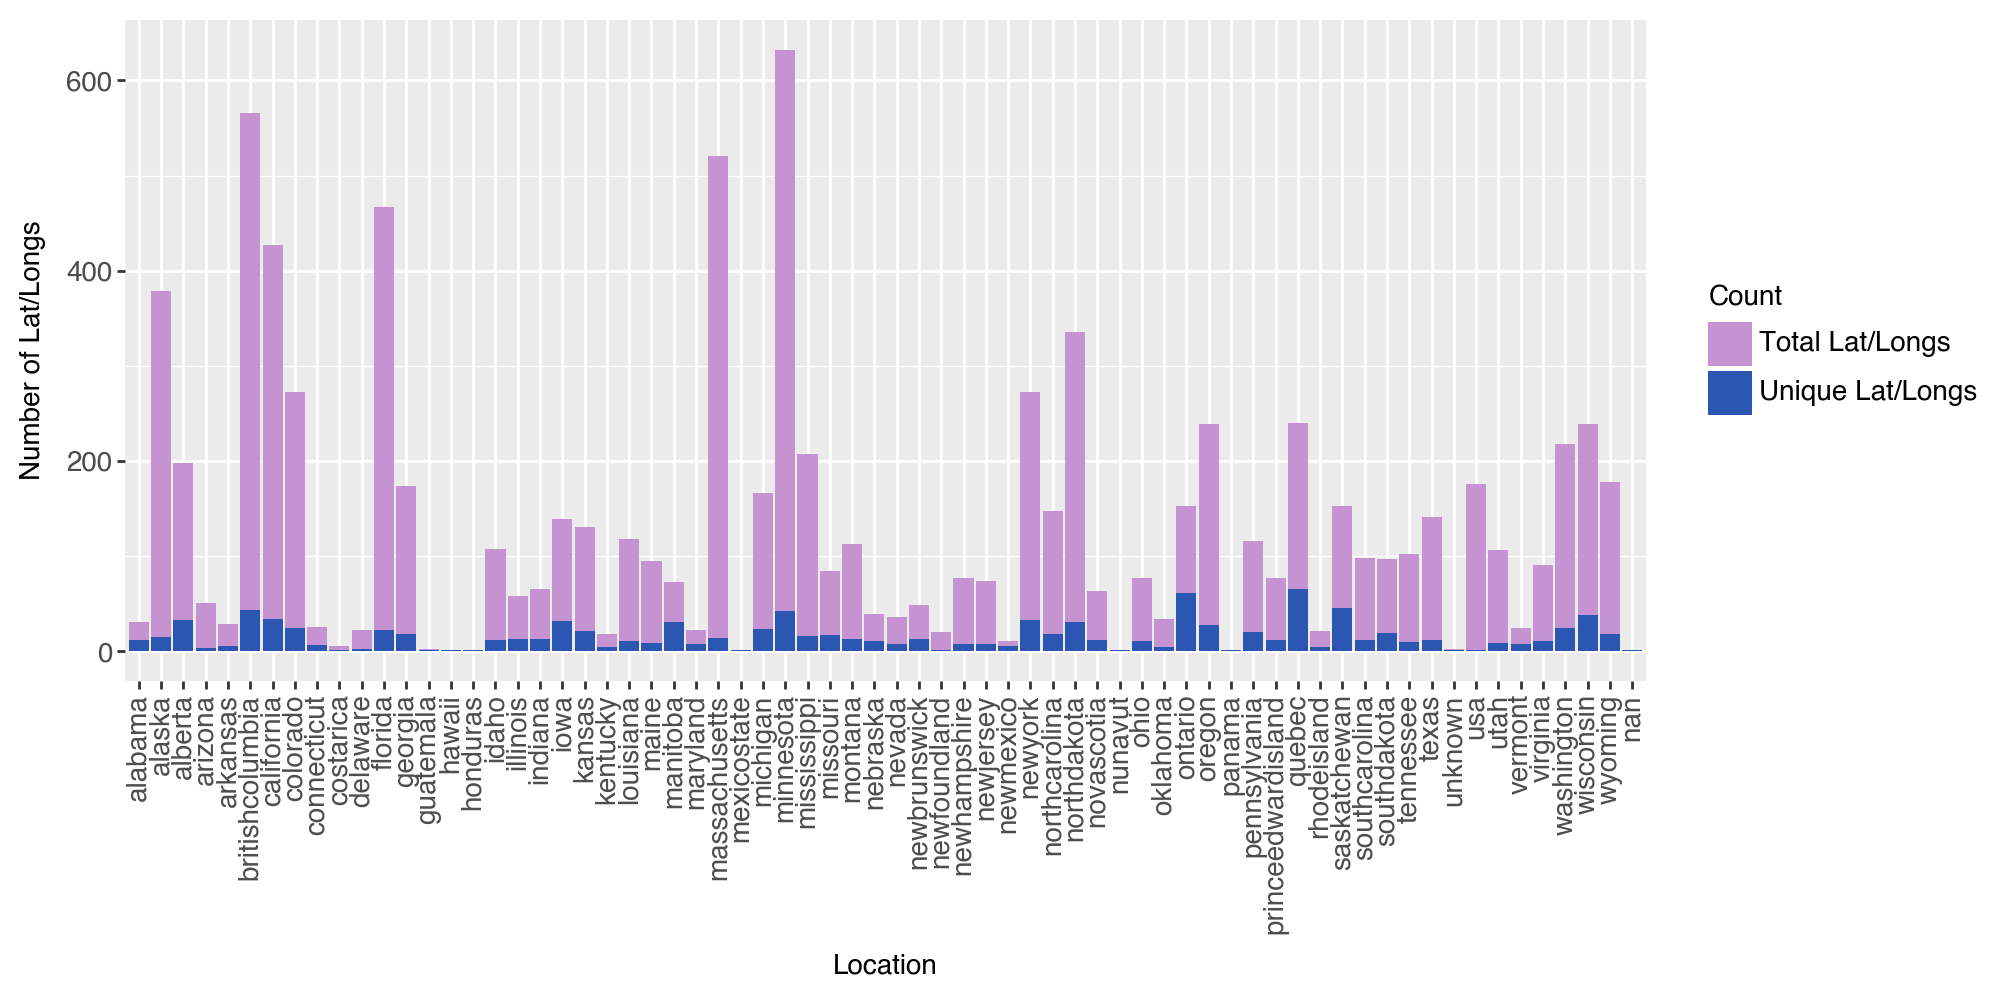

In [16]:
# Plot
uniquelatlong_per_division = (
    ggplot()
    + geom_col(data=ncbibvbrcgis_ha_geodata_wild_SUBSET2, mapping=aes(x='division', fill='Count'), stat='count', position='dodge')
    + geom_col(data=unique_per_division_df, mapping=aes(x='division', y='unique_latlong_count', fill='Count'), position='dodge')
    + scale_fill_manual(values={"total":"#C593D1", "unique": "#2B57B3"}, name="Count", labels={"total":"Total Lat/Longs", "unique": "Unique Lat/Longs"})
    + labs(x='Location', y='Number of Lat/Longs')
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
    + theme(figure_size=(10, 5))
)

uniquelatlong_per_division.show()
#uniquelatlong_per_division.save(filename = './metadata/exploratory_data_analysis/2021-2024_latlongs_by_location.png', height=10, width=20, units = 'in', dpi=750)

In [ ]:
# How frequently is each repeated lat/long seen on each dat

In [32]:
# Function: assigns a number to each unique lat/long in each year_month
def assign_latlong_counts(df):
    # Sort the data for consistency (optional but recommended)
    df = df.sort_values(['year_month', 'lat_long_to_use']).copy()

    # Create a group number for each unique lat/long per year_month
    df['latlong_id'] = (df.groupby('year_month')['lat_long_to_use'].transform(lambda x: x.factorize()[0] + 1))

    return df

In [39]:
with_counts = assign_latlong_counts(ncbibvbrcgis_ha_geodata_wild_SUBSET2)
with_counts.head()
print(with_counts["year_month"].dtypes)

object


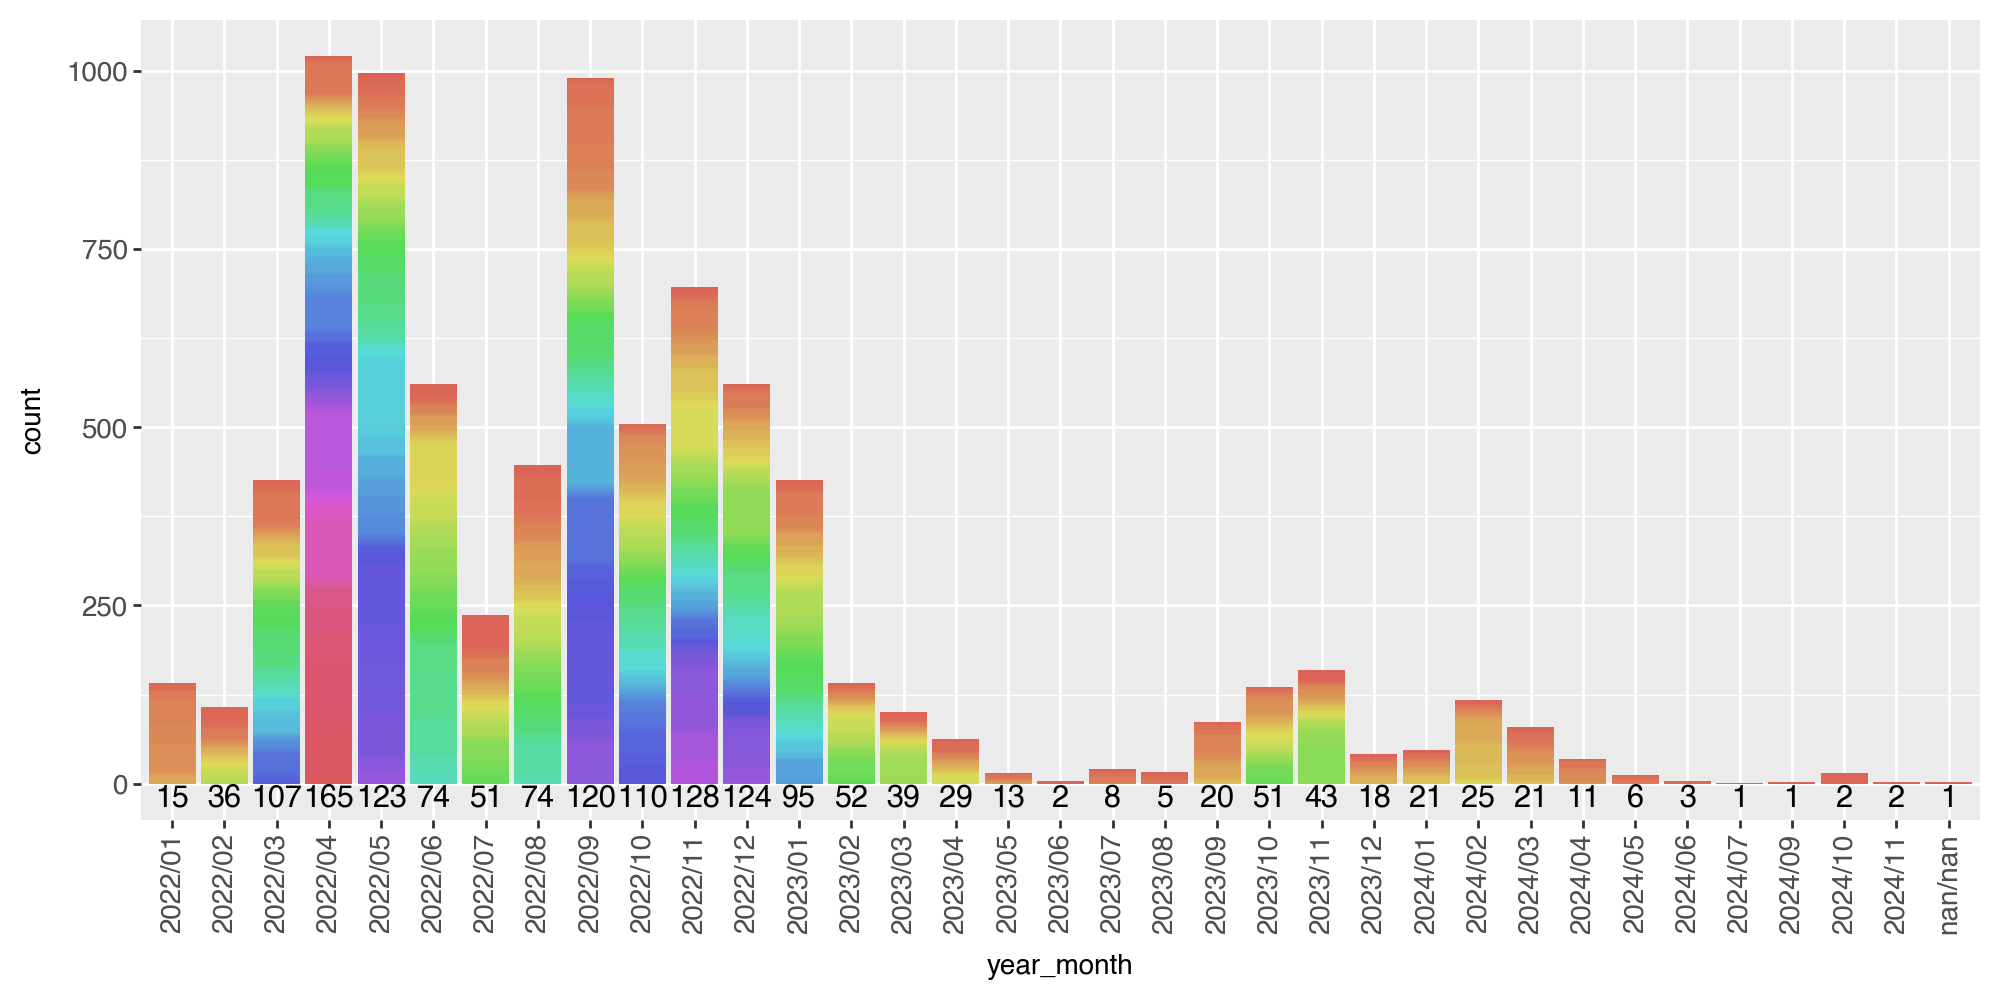

In [50]:
# This plot show the total counts of lat/longs by year-month, colored by the frequency of each unique lat/long

# First, count the frequency of each lat/long in each year_month
latlong_freq = (with_counts.groupby(['year_month', 'latlong_id']).size().reset_index(name='count'))

repeated_latlong_counts = (
    ggplot(latlong_freq, aes(x='year_month', y='count'))
    + geom_col(aes(fill='factor(latlong_id)'))
    + geom_text(data = unique_per_date_df, mapping=aes(x='year_month', y=0, label='unique_latlong_count'), va='top', format_string='{:.0f}')
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10), legend_position = "none")
#    + scale_fill_brewer(type='qual', palette='Set3')
    + theme(figure_size=(10, 5))
)

repeated_latlong_counts.show()

#uniquelatlong_counts.save(filename = './metadata/exploratory_data_analysis/test.png', height=10, width=20, units = 'in', dpi=750)

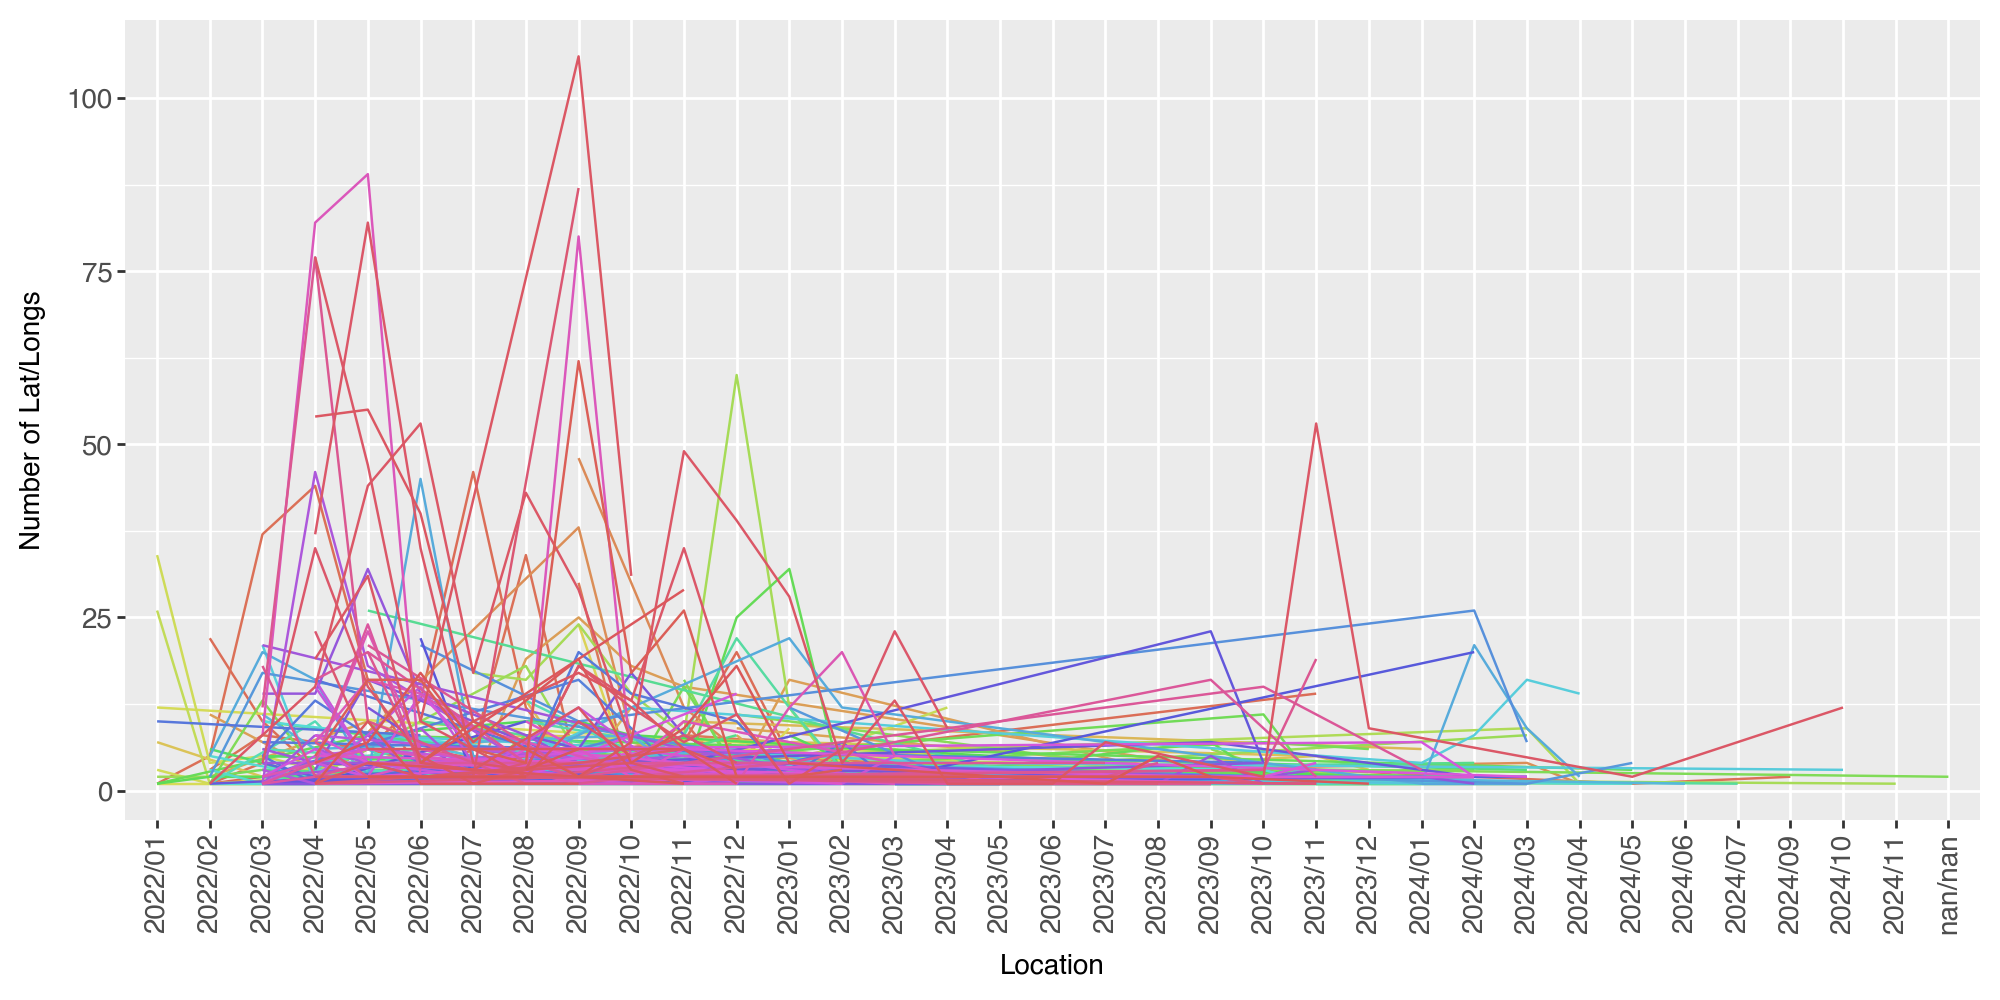

In [71]:
uniquelatlong_counts1 = (
    ggplot(result_df, aes(x='year_month', y='count', color='unique_latlong', group='unique_latlong'))
    + geom_line()
    + labs(x='Location', y='Number of Lat/Longs')
    + theme(
        axis_text_x=element_text(rotation=90),
        text=element_text(size=10),
        legend_position='none',
        figure_size=(10, 5)
    )
)
uniquelatlong_counts1.show()

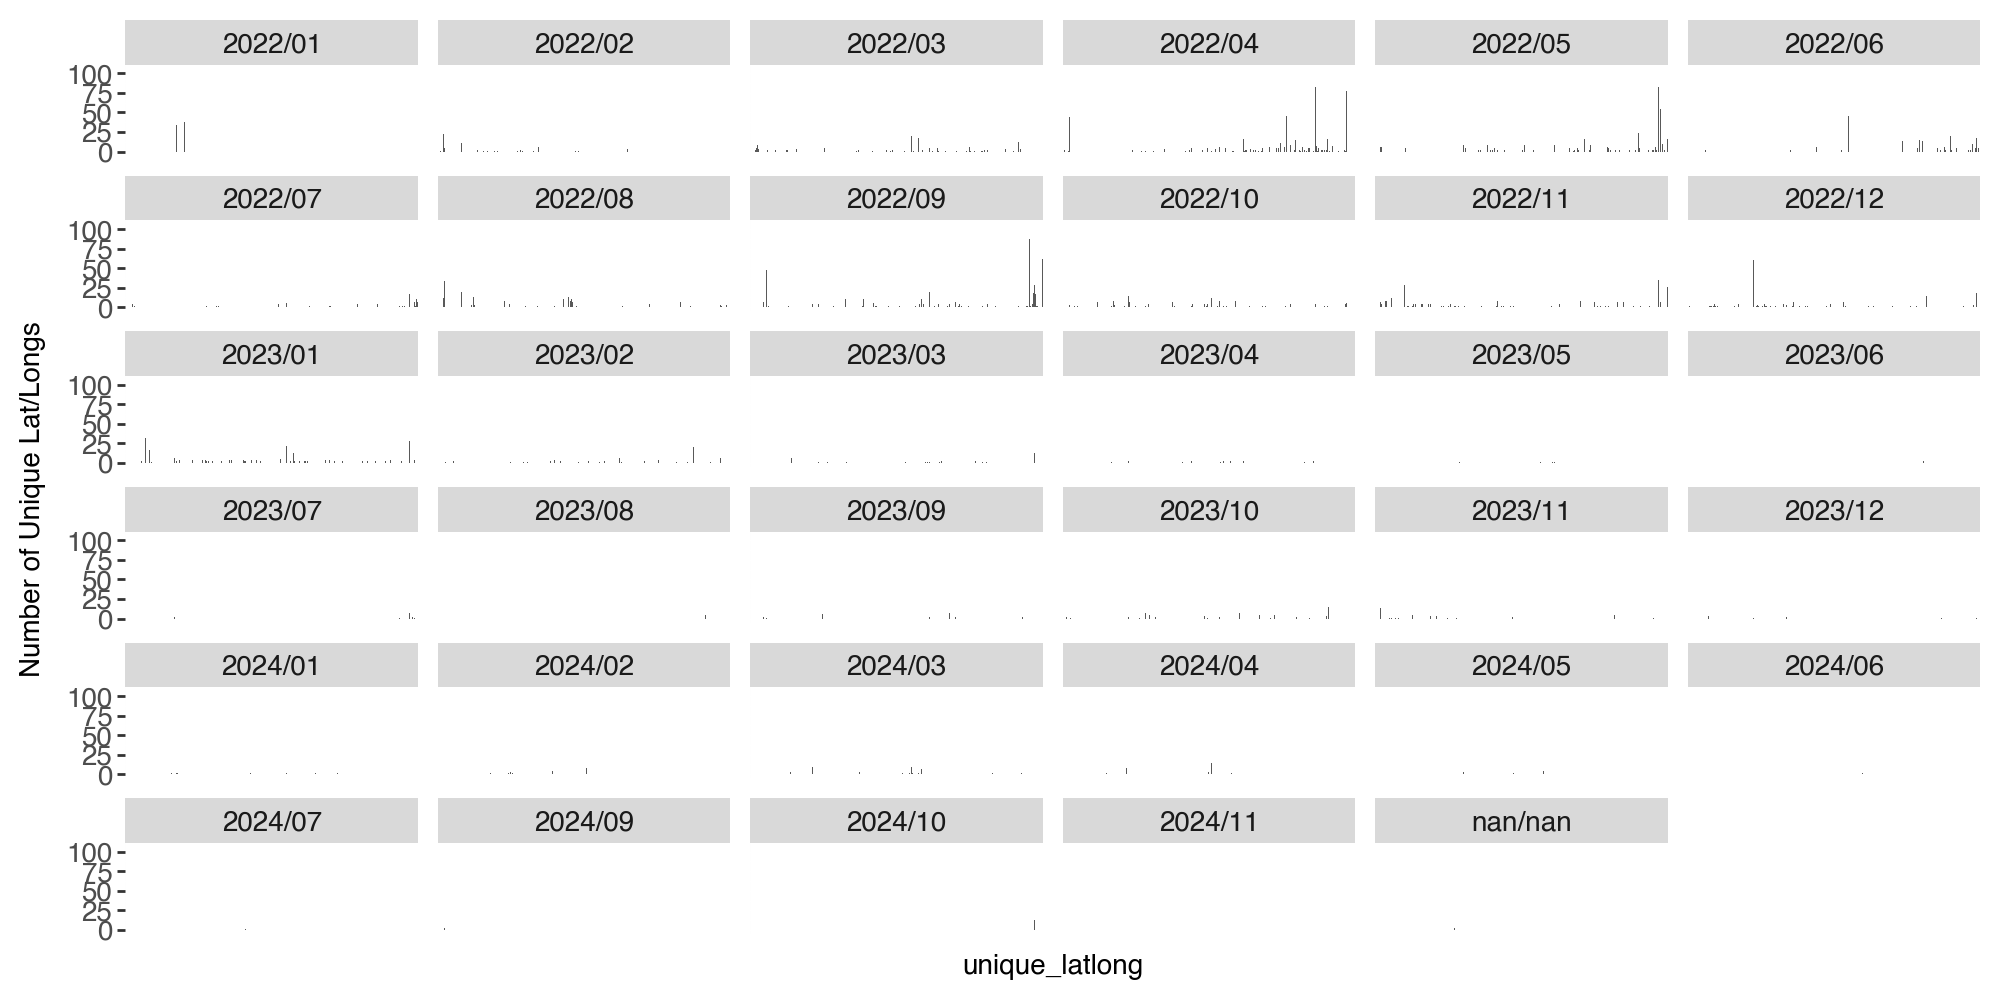

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: /Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/exploratory_data_analysis/test2.png


In [67]:
uniquelatlong_counts2 = (
    ggplot()
    + geom_col(data=result_df, mapping=aes(x='unique_latlong', y = 'count'))
    + facet_wrap('~year_month')
    + labs( y='Number of Unique Lat/Longs')
    + theme(axis_text_x=element_blank(), axis_ticks_major_x=element_blank(), text=element_text(size=10), legend_position='none')
    + theme(figure_size=(10, 5))
)

uniquelatlong_counts2.show()
uniquelatlong_counts2.save(filename = './metadata/exploratory_data_analysis/test.png', height=10, width=20, units = 'in', dpi=750)

In [32]:
# How many full viral sequences from confirmed domestic birds?

ncbibvbrcgis_domestic = ncbibvbrcgis_final[ncbibvbrcgis_final["domesticstatus_combined"] == "domestic"]

strain_counts = ncbibvbrcgis_domestic["strain_title"].value_counts()

all_domestic_full = []

for strain, count in strain_counts.items():
    if count == 8:
        all_domestic_full.append(strain)

print(len(all_domestic_full))

2027


In [ ]:
# Some exploratory data on the detections data as well!

In [32]:
# Read in the detections data

US_DETECT = "./metadata/detections_data/HPAI Detections in Wild Birds (dwnld 2025-01-31).csv"
CAN_DETECT = "./metadata/detections_data/HPAI_IAHP_Wildlife_Faune__file_fichie.csv"

us_detections = pd.read_csv(US_DETECT, sep = ',')
can_detections = pd.read_csv(CAN_DETECT, sep = ',')

In [33]:
# How many detections in United States wild birds?

print(len(us_detections))
print(len(can_detections))

11065
2858


In [40]:
# Function: alter host names

def correct_host_names(df, column):
    df["species_name_altered"] = df[column].copy()
    df["species_name_altered"] = df["species_name_altered"].str.strip()
    df["species_name_altered"] = df["species_name_altered"].str.lower()
    df["species_name_altered"] = df["species_name_altered"].str.replace("-", "")
    df["species_name_altered"] = df["species_name_altered"].str.replace(" ", "")
    df["species_name_altered"] = df["species_name_altered"].str.replace("(unidentified)", "")
    df["species_name_altered"] = df["species_name_altered"].str.replace("(duck)", "")
    df["species_name_altered"] = df["species_name_altered"].str.replace("(gullsandterns)", "")
    df["species_name_altered"] = df["species_name_altered"].str.replace("(anatidae)", "")

    return df

In [41]:
# Correct host names

us_detections_updt = correct_host_names(us_detections, "Bird Species")
can_detections_updt = correct_host_names(can_detections, "Common Name")

In [44]:
# Add host order to the data

# Read in the host-to-order list as a dictionary 
host_to_order = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ',', encoding='latin-1')
host_to_order_dict = host_to_order.set_index("strain_host").to_dict(orient="index")

# Finally, use this dictionary to add an "order" column to the detections
us_detections_updt["host_order"] = us_detections_updt["species_name_altered"].map(lambda strain_host: host_to_order_dict.get(strain_host, {}).get("order"))
can_detections_updt["host_order"] = can_detections_updt["species_name_altered"].map(lambda strain_host: host_to_order_dict.get(strain_host, {}).get("order"))

In [45]:
can_detections_updt.head()

,Province,Common Name,Scientific Name,Animal Class,Bird Group,Collection Date,Status,Result,Strain,Lineage,Result Authorised Date,CCSNAME,species_name_altered,host_order
0,British Columbia,Canada Goose,Branta canadensis,Avian,Waterfowl,2022.05.24,NaN,Confirmed,H5N1,Reassortment EU&NA,2022.06.24,Abbotsford,canadagoose,anseriformes
1,British Columbia,Canada Goose,Branta canadensis,Avian,Waterfowl,2022.06.08,NaN,Confirmed,H5N1,Reassortment EU&NA,2022.08.18,Abbotsford,canadagoose,anseriformes
2,British Columbia,Canada Goose,Branta canadensis,Avian,Waterfowl,2022.06.13,Dead,Confirmed,H5N1,Reassortment EU&NA,2023.02.09,Abbotsford,canadagoose,anseriformes
3,British Columbia,Canada Goose,Branta canadensis,Avian,Waterfowl,2022.06.14,Dead,Confirmed,H5N1,Reassortment EU&NA,2023.02.09,Abbotsford,canadagoose,anseriformes
4,British Columbia,Bald Eagle,Haliaeetus leucocephalus,Avian,Raptor,2022.06.20,NaN,Confirmed,H5N1,Reassortment EU&NA,2022.11.10,Abbotsford,baldeagle,accipitriformes


In [47]:
# Make a concatenated detections dataset
all_detections = pd.concat([us_detections_updt, can_detections_updt], join = "outer", axis = 0)

print(len(all_detections))

13923


In [48]:
# Count the distribution of host orders in the detections data

print(all_detections["host_order"].value_counts())

host_order
anseriformes           8432
accipitriformes        2261
passeriformes           686
charadriiformes         681
strigiformes            617
pelecaniformes          236
suliformes              183
falconiformes           131
columbiformes            88
podicipediformes         75
galliformes              44
procellariiformes        24
gruiformes               20
gaviiformes              19
rheiformes                5
phoenicopteriformes       3
ciconiiformes             2
coraciiformes             1
cathartiformes            1
psittaciformes            1
casuariiformes            1
Name: count, dtype: int64


In [51]:
# Count of detections per year

us_detections_updt["year_detected"] = us_detections_updt["Collection Date"].str.split("/", expand = True)[2]
can_detections_updt["year_detected"] = can_detections_updt["Collection Date"].str.split(".", expand = True)[0]

print(us_detections_updt["year_detected"].value_counts())
print(can_detections_updt["year_detected"].value_counts())

year_detected
2022    6402
2023    3051
2024    1353
2025      65
2021       4
Name: count, dtype: int64
year_detected
2022    1694
2023     574
2024     420
2025     164
2021       6
Name: count, dtype: int64


In [52]:
# Subset to the top 20 host species

host_counts = pd.DataFrame(all_detections["species_name_altered"].value_counts()).reset_index()
host_counts.head()

top20 = host_counts["species_name_altered"].loc[0:19]
print(top20)

0                  mallard
1              canadagoose
2                snowgoose
3          greenwingedteal
4                baldeagle
5             blackvulture
6           bluewingedteal
7            redtailedhawk
8           greathornedowl
9           americanwigeon
10            americancrow
11                 gadwall
12                woodduck
13         northernpintail
14           turkeyvulture
15        northernshoveler
16           cacklinggoose
17    greatblackbackedgull
18             ross'sgoose
19             herringgull
Name: species_name_altered, dtype: object


In [16]:
# How were Anseriformes collected?

anseriformes_only = detections[detections["host_order"] == "anseriformes"]
print(len(anseriformes_only))

print(anseriformes_only["Sampling Method"].value_counts())

7125
Sampling Method
Hunter harvest         3492
Morbidity/Mortality    2247
Live bird              1154
Hunter Harvest          180
Agency harvest           52
Name: count, dtype: int64


In [ ]:
# What are the top 20 reservoir hosts?

reservoir_hosts = detections[(detections["host_order"] == "anseriformes") | (detections["host_order"] == "charadriiformes")]

host_counts_reservoir = pd.DataFrame(reservoir_hosts["Bird Species"].value_counts()).reset_index()

top20_reservoir = host_counts_reservoir["Bird Species"].loc[0:19]
print(top20_reservoir)

In [18]:
# Plot the sequences per state on a map

In [22]:
# Load in the NaturalEarth shapefile as your map
# states_path = "./metadata/ne_110m_admin_1_states_provinces/ne_110m_admin_1_states_provinces.shp"
# states_gdf = gpd.read_file(states_path)

# countries_path = "./metadata/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp"
# countries_gdf = gpd.read_file(countries_path)

In [111]:
# Filter for U.S. states and desired countries

# Filter for US States
# us_states = states_gdf[states_gdf['admin'] == 'United States of America']

# # List of countries to include
# country_list = [
#     "Canada", "Mexico", 
#     # "Panama", "Costa Rica", "Nicaragua",
#     # "Honduras", "El Salvador", "Belize", "Guatemala"
# ]

# selected_countries = countries_gdf[countries_gdf['ADMIN'].isin(country_list)]

In [112]:
# Reproject if needed (should be EPSG:4326 by default)
# selected_countries = selected_countries.to_crs(us_states.crs)

# # Combine both GeoDataFrames
# combined_gdf = pd.concat([us_states, selected_countries], ignore_index=True)

In [23]:
# I have a combined shapefile for North America now

Nam_path = "./metadata/shapefiles/north_america/north_america.shp"
NAm_gdf = gpd.read_file(Nam_path)

NAm_gdf["geometry_name"] = NAm_gdf["name"].combine_first(NAm_gdf["PRNAME"])
columns = ["geometry", "geometry_name", "place", "type", "latitude", "longitude", "fips", "region", "gadm_level"]
NAm_gdf = NAm_gdf.loc[0:, columns]

NAm_gdf = NAm_gdf.to_crs("EPSG:4326")

In [24]:
# Create a DataFrame of lat/lon from the geometries

def geom_to_df(geom, region_name):
    if isinstance(geom, Polygon):
        coords = list(geom.exterior.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiPolygon):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.exterior.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
            # Add NaN to separate parts (important for line-based plotting)
            dfs.append(pd.DataFrame({
                'lon': [np.nan],
                'lat': [np.nan],
                'region': [region_name],
                'group': [f"{region_name}_{i}"]
            }))
        return pd.concat(dfs, ignore_index=True)

    if isinstance(geom, LineString):
        coords = list(geom.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiLineString):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
#            dfs.append(pd.DataFrame({'lon': [np.nan],'lat': [np.nan],'region': [region_name],'group': [f"{region_name}_{i}"]}))
        return pd.concat(dfs, ignore_index=True)

    else:
        return pd.DataFrame(columns=['lon', 'lat', 'region', 'group'])

In [114]:
# Optional cleaning
# combined_gdf = combined_gdf[combined_gdf.is_valid]
# combined_gdf = combined_gdf[~combined_gdf.geometry.is_empty]

In [26]:
# Apply to all rows

map_df = pd.concat([
    geom_to_df(row.geometry, row['geometry_name']) for idx, row in NAm_gdf.iterrows()], ignore_index=True)

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


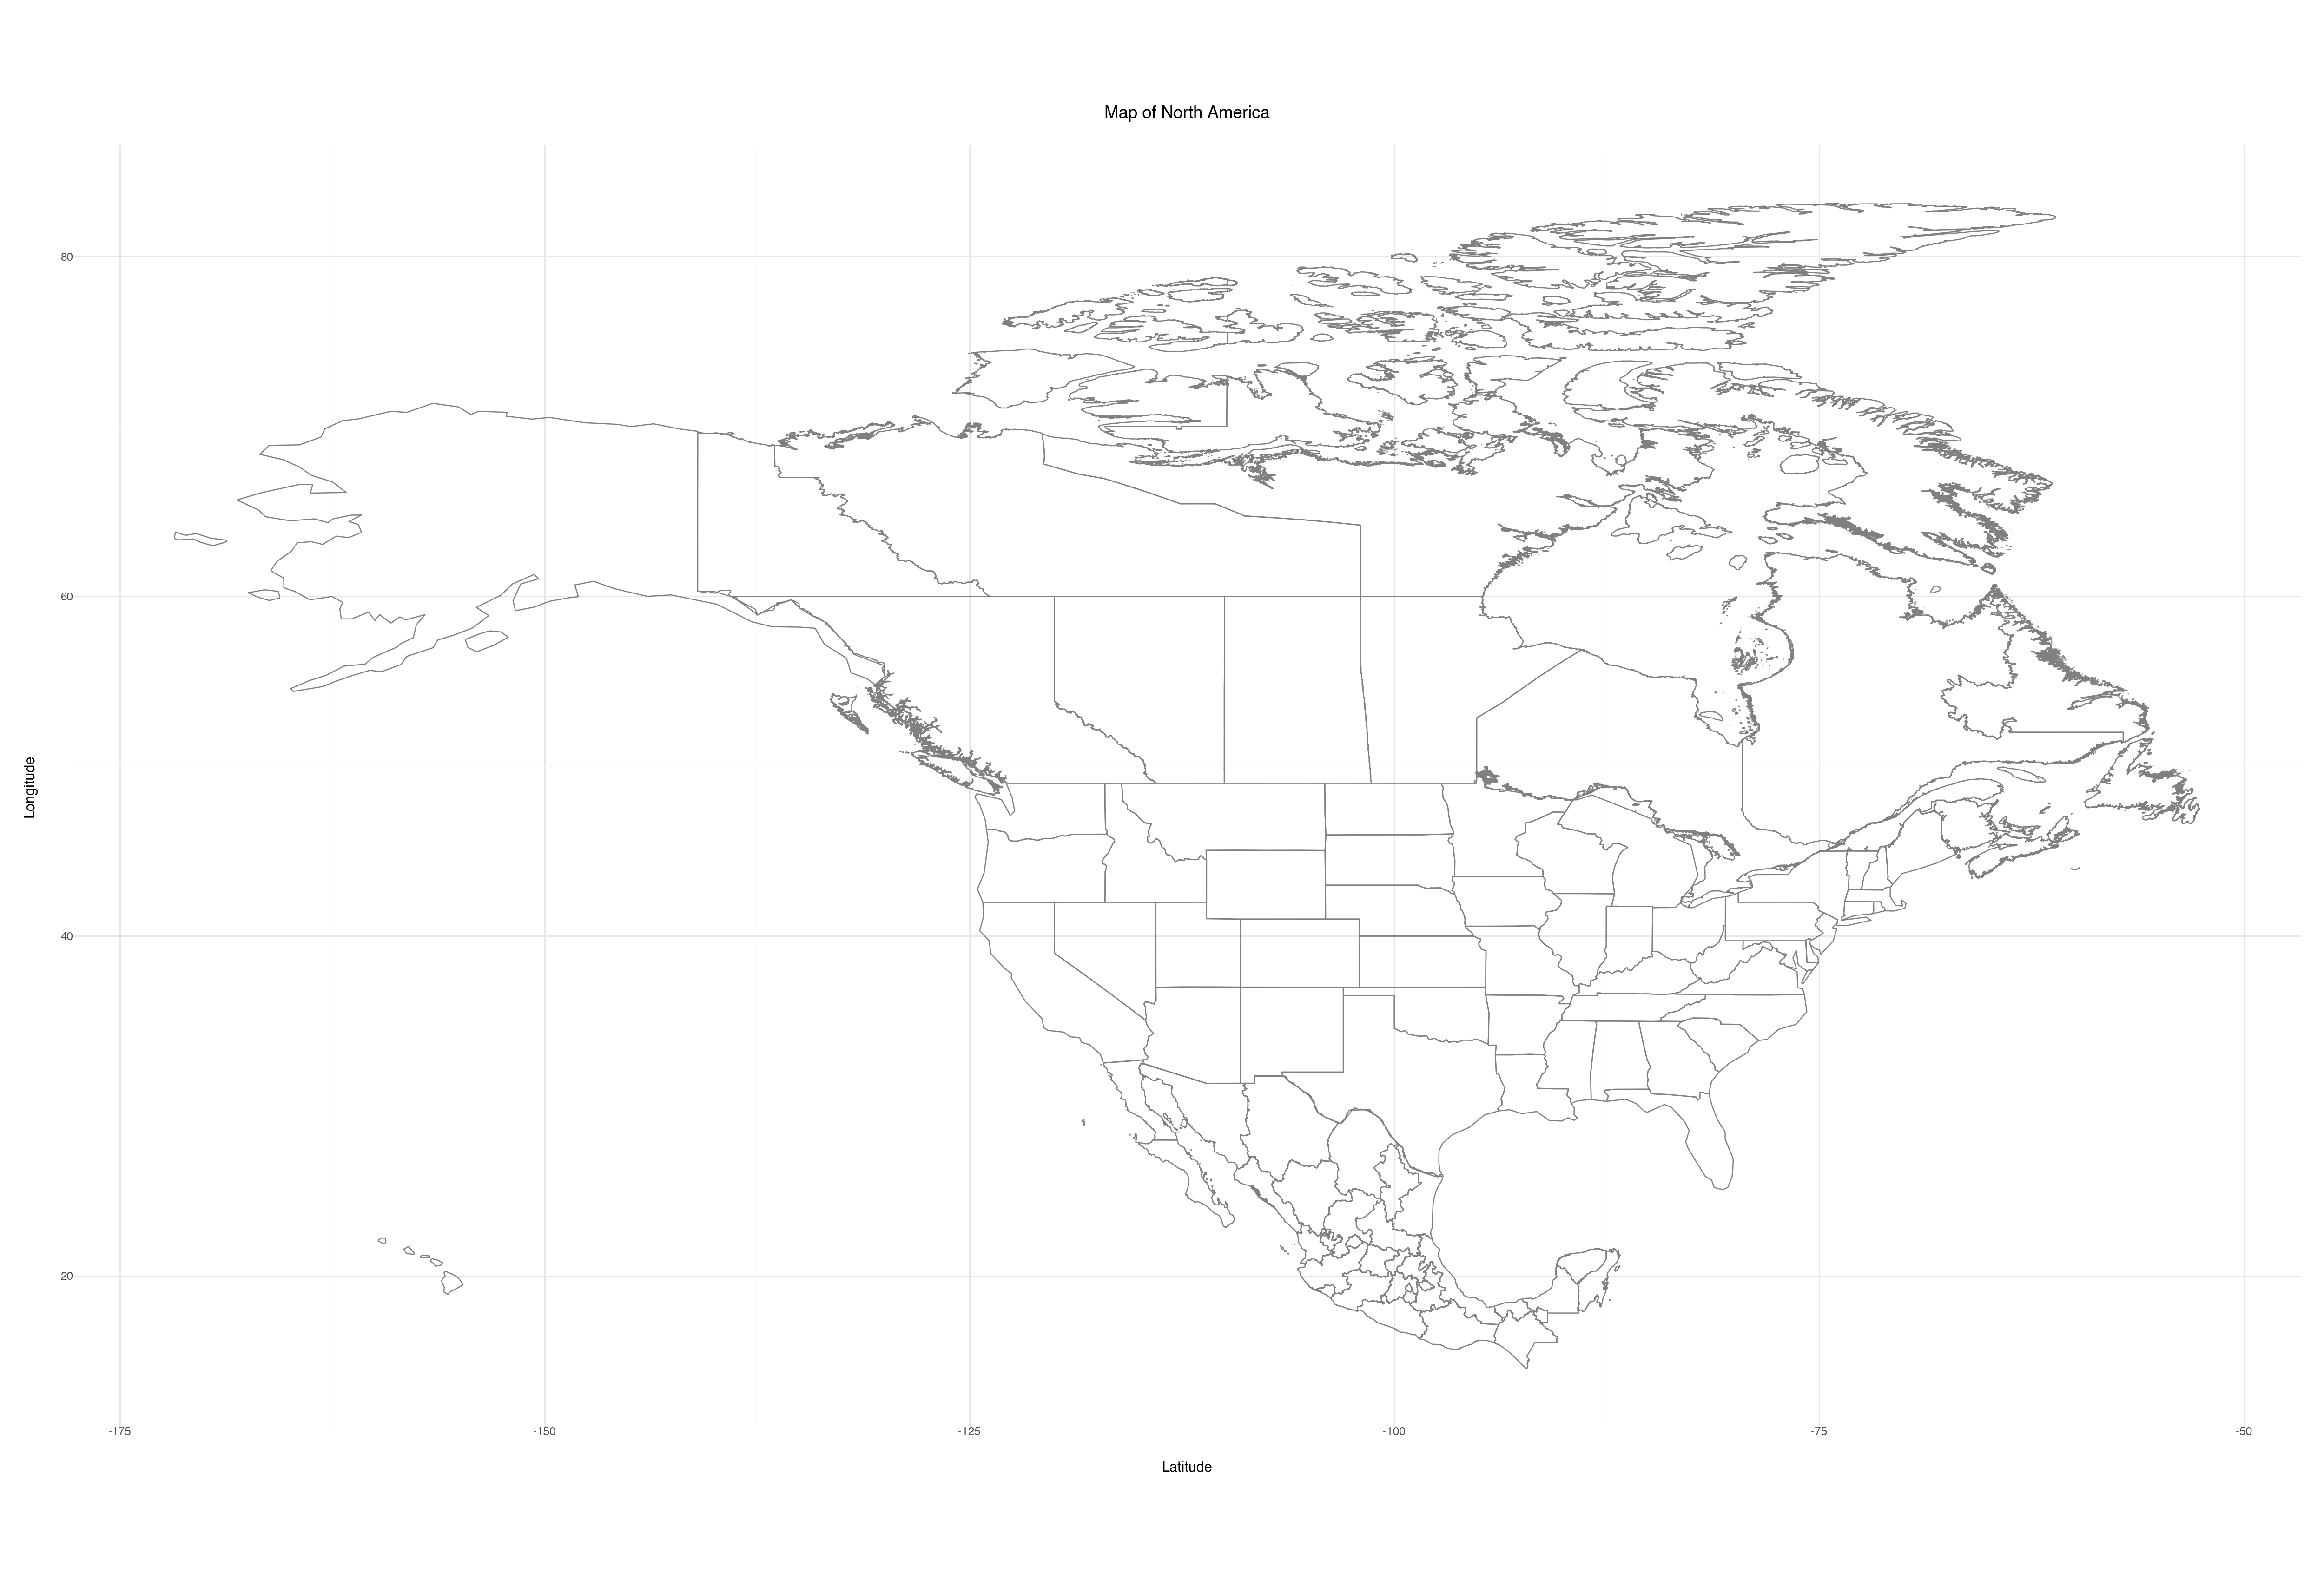

In [28]:
p = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(25, 17)) +
    labs(title='Map of North America', x = "Latitude", y = "Longitude")
)

p.show()

In [29]:
# Get counts of HA sequences per state 
# ncbibvbrcgis_final_HA = ncbibvbrcgis_final[ncbibvbrcgis_final["segment_no"] == 4]
# print(len(ncbibvbrcgis_final_HA))

# ncbibvbrcgis_final_HA_wild = ncbibvbrcgis_final_HA[ncbibvbrcgis_final_HA["domesticstatus_combined"] == "wild"]
# print(len(ncbibvbrcgis_final_HA_wild))

# ncbibvbrcgis_final_HA_wild_2022 = ncbibvbrcgis_final_HA_wild[ncbibvbrcgis_final_HA_wild["year_only"] == 2022]
# print(len(ncbibvbrcgis_final_HA_wild_2022))

# Get counts per state
# finalmeta_ha_state_counts = ncbibvbrcgis_final_HA_wild['division'].value_counts().reset_index()
#finalmeta_ha_state_counts = ncbibvbrcgis_final_HA_wild_2022['division'].value_counts().reset_index()
metadata_state_counts = ncbibvbrcgis_final_drop_nan_date["division"].value_counts().reset_index()

# finalmeta_ha_state_counts.columns = ['location', 'count']
metadata_state_counts.columns = ["location", "count"]

In [37]:
# For clarity's sake, remove sequences from Central America

remove_locations = ["usa", "unknown", "costarica", "honduras", "panama", "guatemala"]

# finalmeta_ha_state_counts_filtered = finalmeta_ha_state_counts[~finalmeta_ha_state_counts["location"].isin(remove_locations)]
metadata_state_counts_filtered = metadata_state_counts[~metadata_state_counts["location"].isin(remove_locations)]
# print(finalmeta_ha_state_counts[finalmeta_ha_state_counts["location"].isin(remove_locations)])

In [38]:
# Import lat/longs for each division

state_latlongs = pd.read_csv("./metadata/helpful_lists/flywayregions_biggerlist.csv", sep = ',')

In [39]:
# Merge counts and coordinates
# bubble_data = pd.merge(finalmeta_ha_state_counts_filtered, state_latlongs, on='location', how='left')
bubble_data = pd.merge(metadata_state_counts_filtered, state_latlongs, on='location', how='left')

In [40]:
bubble_data.head()

,location,count,latitude,longitude,flyway,geo_region_na,type
0,britishcolumbia,566,54.9170,-125.9527,PacificFlyway,Canada,state
1,massachusetts,439,42.2596,-71.8083,AtlanticFlyway,Northeast,state
2,minnesota,408,46.2810,-94.3046,MississippiFlyway,Midwest,state
3,florida,319,28.6282,-82.4426,AtlanticFlyway,South,state
4,northdakota,272,47.4499,-100.4674,CentralFlyway,Midwest,state


In [58]:
seqs_per_location_map = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=bubble_data, mapping=aes(x='longitude', y='latitude', size='count', fill = 'flyway'), alpha=0.6) +
    scale_fill_manual(values = {"AtlanticFlyway":"#AA7722", "MississippiFlyway":"#5E9B82", "CentralFlyway":"#C593D1", "PacificFlyway":"#2B57B3", "unknown":"#9C9C9C", "nan":"#9C9C9C"},
                      name = "Flyway",
                      labels = {"AtlanticFlyway":"Atlantic", "MississippiFlyway":"Mississippi", "CentralFlyway":"Central", "PacificFlyway":"Pacific", "unknown":"Unknown", "nan":"Unknown"}) +
    scale_size_continuous(name="Count", range=(3, 15)) +
    coord_fixed() +
    theme(text=element_text(size=24), legend_title=element_text(size=30), legend_text=element_text(size=24), legend_key_size=10) + 
    theme(figure_size=(15, 10)) +
    theme_minimal() +
    labs(title='Sequence Counts by Location')
)

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


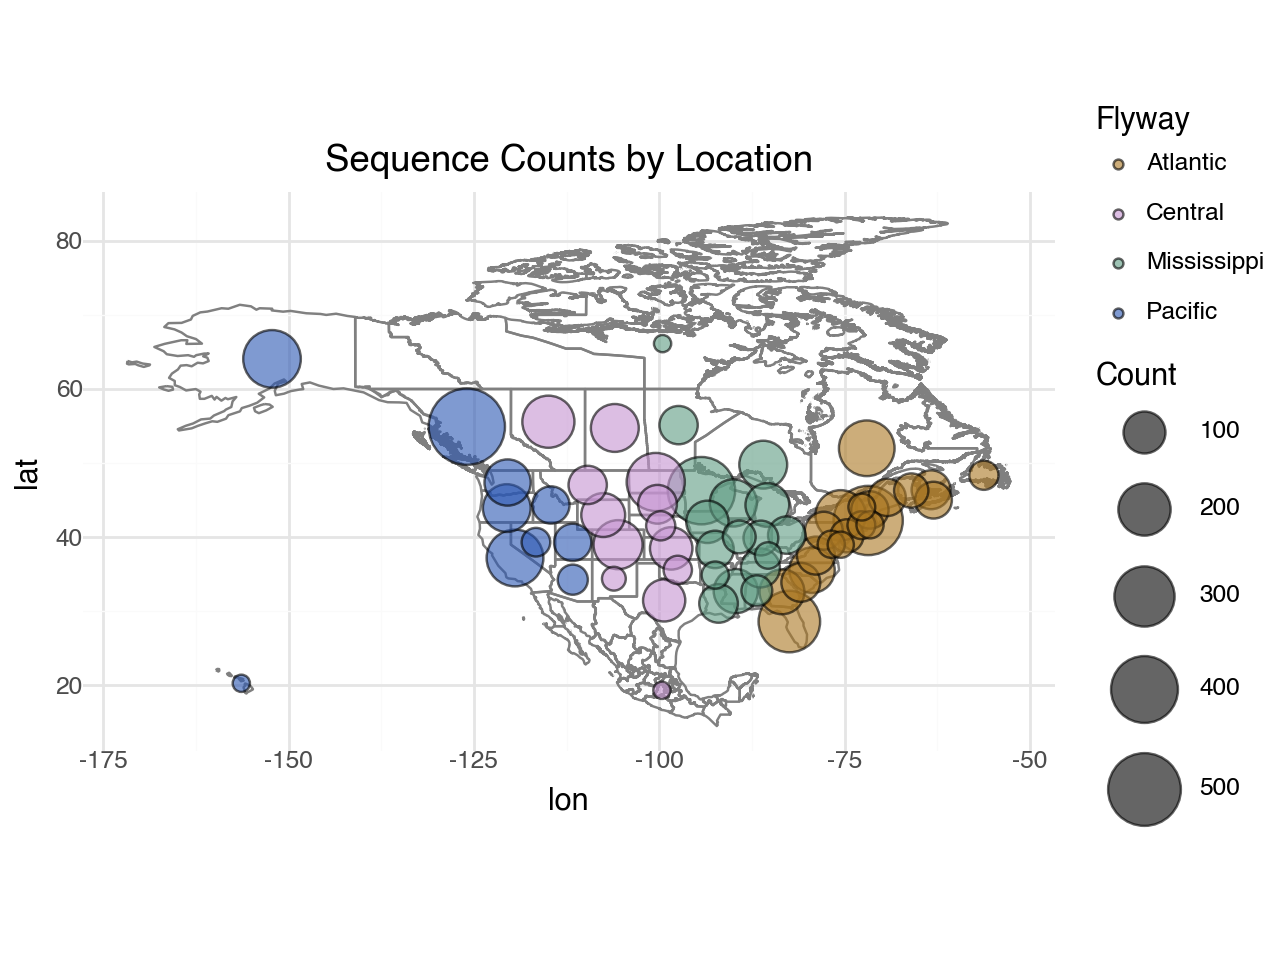

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./metadata/exploratory_data_analysis/HAseqs_per_location_map.png
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


In [59]:
seqs_per_location_map.show()
seqs_per_location_map.save(filename = './metadata/exploratory_data_analysis/HAseqs_per_location_map.png', height=10, width=20, units = 'in', dpi=750)
#seqs_per_location_map.save(filename = './metadata/exploratory_data_analysis/2022seqs_per_location_map.png', height=10, width=20, units = 'in', dpi=750)

In [9]:
subtype_analysis = pd.read_csv("./metadata/sequence_metadata/full_data_subtypes.tsv", sep = '\t')

subtype_analysis["not_h5n1"] = None

for idx, row in subtype_analysis.iterrows():
    
    gisaid_na = row["subtype"]
    ncbi_na = row["Genotype"]
    bvbrc_na = row["N_type"]
    
    if gisaid_na == "h5n1" or ncbi_na == "H5N1" or bvbrc_na == "1":
        subtype_analysis.at[idx, "not_h5n1"] = "h5n1"
    else:
        subtype_analysis.at[idx, "not_h5n1"] = "not"

In [12]:
print(subtype_analysis["not_h5n1"].value_counts())

# 2% of data is not H5N1

not_h5n1
h5n1    87526
not      2028
Name: count, dtype: int64
